# Generative AI · Assignment 1 — Latent Spaces, and Why GANs Are Hard to Train

**FAST-NUCES Lahore · Fall 2026 · Roll 25L-8006**

Parts 0 and A are complete and runnable. Parts B–E still carry the starter's TODO blocks
and will be filled in next.

Settings → Accelerator = **GPU (T4 or P100)**, Internet = **On**
(MNIST needs it once), and the CelebA dataset attached under *Add Input*.


---
## 0 · Setup

In [1]:
# ---- YOUR ROLL NUMBER -------------------------------------------------------
ROLL = "25L-8006"
# -----------------------------------------------------------------------------

R    = int(ROLL[-2:])                 # last two digits
SEED = int(ROLL[-4:])                 # last four digits  -> the seed for every run

HELD_OUT_DIGIT = R % 10                                  # Part B anomaly class
MY_DIGITS      = sorted({(R + 3 * k) % 10 for k in range(6)})
for d in range(10):                                      # top up if the set is short
    if len(MY_DIGITS) == 6: break
    if d not in MY_DIGITS: MY_DIGITS = sorted(MY_DIGITS + [d])
ATTRS      = ["Eyeglasses", "Male", "Young", "Blond_Hair", "Wearing_Hat", "Mouth_Slightly_Open"]
MY_ATTR    = ATTRS[R % 6]

print(f"roll {ROLL}   R={R}   SEED={SEED}")
print(f"held-out digit : {HELD_OUT_DIGIT}")
print(f"my six digits  : {MY_DIGITS}")
print(f"my attribute   : Smiling  +  {MY_ATTR}")

roll 25L-8006   R=6   SEED=8006
held-out digit : 6
my six digits  : [1, 2, 5, 6, 8, 9]
my attribute   : Smiling  +  Eyeglasses


In [2]:
import os, json, math, random, csv, time, glob
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, TensorDataset, Dataset
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt
from scipy import linalg
from PIL import Image

DEV = "cuda" if torch.cuda.is_available() else "cpu"
print(DEV, torch.__version__)
if DEV == "cpu":
    print("WARNING: no GPU. Settings -> Accelerator -> GPU T4 x2 or P100.")

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()
for d in ["figures", "logs", "ckpt", "cache"]:
    os.makedirs(d, exist_ok=True)

METRICS = {}                       # everything you quote in the report goes in here
if os.path.exists("metrics.json"):
    METRICS = json.load(open("metrics.json"))

def record(key, value):
    METRICS[key] = value
    json.dump(METRICS, open("metrics.json", "w"), indent=2, default=float)
    print(f"  {key} = {value}")

cuda 2.10.0+cu128


### 0.1 · Plot helpers

In [3]:
def show_grid(imgs, nrow=8, title=None, save=None, figsize=(10, 4)):
    """imgs: (N,C,H,W) tensor in [0,1] (or [-1,1] -- it is detected and rescaled)."""
    x = imgs.detach().cpu().float()
    if x.min() < -0.01: x = (x + 1) / 2
    g = torchvision.utils.make_grid(x.clamp(0, 1), nrow=nrow, padding=2, pad_value=1)
    plt.figure(figsize=figsize)
    plt.imshow(g.permute(1, 2, 0).squeeze(), cmap="gray" if g.shape[0] == 1 else None)
    plt.axis("off")
    if title: plt.title(title, fontsize=11)
    plt.tight_layout()
    if save: plt.savefig(save, dpi=140, bbox_inches="tight")
    plt.show()


def strip(imgs, labels=None, title=None, save=None):
    """One row of images with optional per-image captions -- use this for interpolations."""
    x = imgs.detach().cpu().float()
    if x.min() < -0.01: x = (x + 1) / 2
    n = x.shape[0]
    fig, ax = plt.subplots(1, n, figsize=(1.35 * n, 1.75))
    for i in range(n):
        im = x[i].clamp(0, 1).permute(1, 2, 0).squeeze()
        ax[i].imshow(im, cmap="gray" if x.shape[1] == 1 else None)
        ax[i].axis("off")
        if labels is not None: ax[i].set_title(str(labels[i]), fontsize=8)
    if title: fig.suptitle(title, fontsize=11, y=1.06)
    plt.tight_layout()
    if save: plt.savefig(save, dpi=140, bbox_inches="tight")
    plt.show()


def row_panel(rows, row_labels, ncol=8, title=None, save=None, col_labels=None):
    """Rows of images with a label down the left edge -- used by A1 and A2."""
    fig, axes = plt.subplots(len(rows), ncol, figsize=(1.25 * ncol, 1.38 * len(rows)),
                             squeeze=False)
    for r, imgs in enumerate(rows):
        x = imgs.detach().cpu().float()
        if x.min() < -0.01: x = (x + 1) / 2
        for c in range(ncol):
            ax = axes[r][c]; ax.set_xticks([]); ax.set_yticks([])
            for s in ax.spines.values(): s.set_visible(False)
            if c < len(x):
                ax.imshow(x[c].clamp(0, 1).permute(1, 2, 0).squeeze(),
                          cmap="gray" if x.shape[1] == 1 else None)
            else:
                ax.axis("off")
            if c == 0:
                ax.set_ylabel(row_labels[r], fontsize=8, rotation=0,
                              ha="right", va="center", labelpad=6)
            if r == 0 and col_labels is not None:
                ax.set_title(str(col_labels[c]), fontsize=7)
    if title: fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    if save: plt.savefig(save, dpi=140, bbox_inches="tight")
    plt.show()

### 0.2 · CSV logger for training runs — **do not delete**

In [ ]:
class RunLog:
    """Writes one row per iteration. Several questions in the handout ask for a specific
    iteration number that can only come from this file."""
    COLS = ["iter", "d_loss", "g_loss", "D_x", "D_G_z", "g_grad_norm"]

    def __init__(self, name):
        self.path = f"logs/{name}.csv"
        self.f = open(self.path, "w", newline="")
        self.w = csv.writer(self.f); self.w.writerow(self.COLS)
        self.rows = []

    def __call__(self, it, d_loss, g_loss, D_x, D_G_z, g_grad_norm):
        row = [it, float(d_loss), float(g_loss), float(D_x), float(D_G_z), float(g_grad_norm)]
        self.rows.append(row); self.w.writerow(row)
        if it % 200 == 0: self.f.flush()

    def close(self):
        self.f.flush(); self.f.close()
        return np.array(self.rows)


def grad_norm(module):    #Gradient monitor
    """L2 norm of the gradient of the FIRST parameter tensor of `module`.
    Call it after loss.backward() and before optimiser.step()."""
    for prm in module.parameters():
        if prm.grad is not None:
            return prm.grad.detach().norm(2).item()
    return 0.0


def collapse_iteration(log_array, frac=0.01, ref_iter=100):   
    """Part C1: the first iteration at which the generator gradient norm falls below
    `frac` of its value at iteration `ref_iter`.  Returns (iteration, ref_value)."""
    it, gn = log_array[:, 0], log_array[:, 5]
    ref = float(np.interp(ref_iter, it, gn))
    below = np.where((it > ref_iter) & (gn < frac * ref))[0]
    return (int(it[below[0]]) if len(below) else None), ref

---
## 1 · Data

MNIST downloads automatically (Internet must be On the first time). CelebA is read
straight from the dataset  attached under **Add Input** — no download.

In [5]:
# ---------------- MNIST ----------------
mnist_tf = transforms.ToTensor()                        # [0,1], shape (1,28,28)
mnist_tr = torchvision.datasets.MNIST("data", train=True,  download=True, transform=mnist_tf)
mnist_te = torchvision.datasets.MNIST("data", train=False, download=True, transform=mnist_tf)

def subset_by_digits(ds, digits):
    idx = [i for i, y in enumerate(ds.targets.tolist()) if y in digits]
    return Subset(ds, idx)

def exclude_digit(ds, digit):
    idx = [i for i, y in enumerate(ds.targets.tolist()) if y != digit]
    return Subset(ds, idx)

mnist_mine = subset_by_digits(mnist_tr, MY_DIGITS)       # Parts C, D, E
print(f"MNIST train {len(mnist_tr)} | my six digits {len(mnist_mine)}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 10.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 338kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.10MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.9MB/s]

MNIST train 60000 | my six digits 35839


### 1.1 · CelebA 64×64 — Kaggle

PyTorch tensor shaped as (N, 3, 64, 64). N is your number of images (the assignment says 30,000 is enough), 3 represents the RGB color channels, and 64, 64 means the images must be centre-cropped to 148x148 and then resized down to 64x64 pixels.

In [ ]:
# ---------------- CelebA 64x64 (Kaggle) ----------------
IMG, N_CELEBA = 64, 30000          # 30k images is plenty for this assignment
SLUG = "jessicali9530/celeba-dataset"

SEARCH_ROOTS = [
    "/kaggle/input",                              # attached dataset  <- the normal case
    "/kaggle/working/data",                       # downloaded by the fallback below
    os.path.expanduser("~/.cache/kagglehub"),     # kagglehub cache
    "data",                                       # local / Colab
]

celeba_tf = transforms.Compose([
    transforms.CenterCrop(148),     # the standard CelebA crop: drops background, keeps the face
    transforms.Resize(IMG),
    transforms.ToTensor(),
])


def _dirs_with_jpgs(pattern):
    out = []
    for c in glob.glob(pattern, recursive=True):
        if os.path.isdir(c):
            try:
                if any(f.endswith(".jpg") for f in os.listdir(c)[:50]): out.append(c)
            except OSError:
                pass
    return out


def _find_image_dir(roots=None):
    """Deepest directory under any known root that actually holds the aligned jpgs."""
    for root in (roots or SEARCH_ROOTS):
        if not os.path.isdir(root): continue
        hits = (_dirs_with_jpgs(f"{root}/*/img_align_celeba/img_align_celeba") or
                _dirs_with_jpgs(f"{root}/*/img_align_celeba") or
                _dirs_with_jpgs(f"{root}/**/img_align_celeba"))
        if hits: return sorted(hits, key=len, reverse=True)[0]
    return None


def _find_attr_file(roots=None):
    for root in (roots or SEARCH_ROOTS):
        if not os.path.isdir(root): continue
        for pat in ("list_attr_celeba.csv", "list_attr_celeba.txt"):
            hits = glob.glob(f"{root}/**/{pat}", recursive=True)
            if hits: return sorted(hits, key=len)[0]
    return None


def load_celeba():
    """Attached Kaggle dataset first (no network). kagglehub / Kaggle CLI only as a
    fallback. Returns (image_root, attr_path)."""
    root, attr = _find_image_dir(), _find_attr_file()
    if root and attr:
        print(f"CelebA found on disk\n  images : {root}\n  attrs  : {attr}")
        return root, attr

    print("Not on disk -> downloading (~1.4 GB, needs Internet = On).")
    try:
        import kagglehub
        print("kagglehub ->", kagglehub.dataset_download(SLUG))
    except Exception as e:
        print("kagglehub failed:", repr(e))
        import subprocess
        dest = "/kaggle/working/data/celeba"; os.makedirs(dest, exist_ok=True)
        r = subprocess.run(["kaggle", "datasets", "download", "-d", SLUG, "-p", dest, "--unzip"],
                           capture_output=True, text=True)
        print((r.stdout or "")[-1000:], (r.stderr or "")[-1000:])

    root, attr = _find_image_dir(), _find_attr_file()
    if not (root and attr):
        print("\nVisible under /kaggle/input:")
        for d in sorted(glob.glob("/kaggle/input/*")): print("  ", d)
        raise FileNotFoundError("CelebA not found. Attach jessicali9530/celeba-dataset "
                                "under Add Input, or switch Internet on.")
    print(f"ready\n  images : {root}\n  attrs  : {attr}")
    return root, attr


def read_attr_table(attr_path):
    """Handles the Kaggle .csv and the original .txt. Returns (files, names, values)."""
    if attr_path.endswith(".csv"):
        import pandas as pd
        df    = pd.read_csv(attr_path)
        files = df.iloc[:, 0].astype(str).tolist()
        names = list(df.columns[1:])
        vals  = df.iloc[:, 1:].to_numpy()
    else:
        lines = open(attr_path).read().strip().split("\n")
        names = lines[1].split()
        files, rows = [], []
        for ln in lines[2:]:
            parts = ln.split()
            files.append(parts[0]); rows.append([int(v) for v in parts[1:]])
        vals = np.array(rows)
    order = np.argsort(files)                     # lock filename <-> attribute-row alignment
    return [files[i] for i in order], names, vals[order]

"""_CelebaFiles decodes the images and multiplies them by 255 to save 
them as torch.uint8 (1-byte integers)."""

class _CelebaFiles(Dataset):
    """Used once, to turn jpgs into a cached uint8 tensor (parallel decode)."""
    def __init__(self, root, files): self.root, self.files = root, files
    def __len__(self): return len(self.files)
    def __getitem__(self, i):
        img = Image.open(os.path.join(self.root, self.files[i])).convert("RGB")
        return (celeba_tf(img) * 255).round().to(torch.uint8)


def build_celeba(n=None, workers=2):
    """(u8 tensor (n,3,64,64), {attr_name: bool array}). Cached: re-runs cost seconds."""
    n = N_CELEBA if n is None else n
    cache = f"cache/celeba_{IMG}_{n}.pt"
    if os.path.exists(cache):
        blob = torch.load(cache, weights_only=False)
        print(f"loaded cache {cache}  {tuple(blob['x'].shape)}")
        return blob["x"], blob["attr"]

    root, attr_path = load_celeba()
    files, names, vals = read_attr_table(attr_path)
    have    = set(os.listdir(root))
    keep    = [i for i, f in enumerate(files) if f in have][:n]
    files_k = [files[i] for i in keep]
    attr    = {nm: (vals[keep, j] > 0) for j, nm in enumerate(names)}

    t0 = time.time()
    dl = DataLoader(_CelebaFiles(root, files_k), batch_size=256,
                    num_workers=workers, shuffle=False)
    x, i = torch.empty(len(files_k), 3, IMG, IMG, dtype=torch.uint8), 0
    for b in dl:
        x[i:i + len(b)] = b; i += len(b)
        print(f"  decoded {i}/{len(files_k)}", end="\r")
    print(f"\ndecoded {i} images in {time.time() - t0:.0f}s")
    torch.save({"x": x, "attr": attr}, cache)
    return x, attr

"""CelebaDS custom dataset wrapper pulls the integer image from RAM and 
dynamically divides it by 255.0 (self.u8[self.idx[i]].float() / 255.0) 
to convert it back to a [0,1] float just in time for the neural network to 
process it."""
class CelebaDS(Dataset):
    """uint8 held in RAM -> float [0,1] per item: ~370 MB instead of ~1.5 GB."""
    def __init__(self, u8, idx=None):
        self.u8  = u8
        self.idx = np.arange(len(u8)) if idx is None else np.asarray(idx)
    def __len__(self): return len(self.idx)
    def __getitem__(self, i): return self.u8[self.idx[i]].float() / 255.0

In [ ]:
_root, _attr_path = load_celeba()
_files, _names, _vals = read_attr_table(_attr_path)
_have = set(os.listdir(_root))
print("images on disk :", len(_have))
print("attr rows      :", len(_files), "| attrs:", len(_names))
print("filenames match:", sum(f in _have for f in _files[:2000]), "/ 2000 of the first rows")
print("Smiling at col", _names.index("Smiling"), "| Eyeglasses at col", _names.index("Eyeglasses"))
print("values seen    :", sorted(set(np.unique(_vals).tolist())))

CelebA found on disk
  images : /kaggle/input/datasets/jessicali9530/celeba-dataset/img_align_celeba/img_align_celeba
  attrs  : /kaggle/input/datasets/jessicali9530/celeba-dataset/list_attr_celeba.csv
  decoded 30000/30000
decoded 30000 images in 154s
CelebA tensor (30000, 3, 64, 64)  dtype=torch.uint8
  Smiling                +1:  14259   -1:  15741
  Eyeglasses             +1:   1946   -1:  28054
train 27000 | val 3000


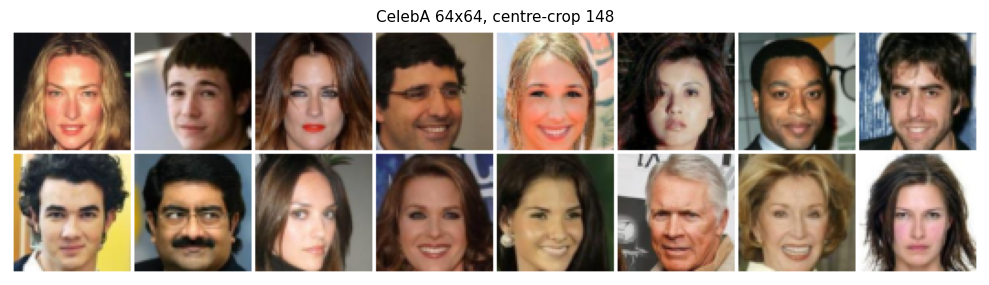

In [8]:
celeba_u8, celeba_attr = build_celeba()
N = len(celeba_u8)
print(f"CelebA tensor {tuple(celeba_u8.shape)}  dtype={celeba_u8.dtype}")
for a in ["Smiling", MY_ATTR]:
    v = celeba_attr[a]
    print(f"  {a:22s} +1: {int(v.sum()):6d}   -1: {int((~v).sum()):6d}")

set_seed()
perm  = np.random.permutation(N)
n_val = max(8, int(0.10 * N))
val_idx, tr_idx = perm[:n_val], perm[n_val:]
celeba_tr, celeba_va = CelebaDS(celeba_u8, tr_idx), CelebaDS(celeba_u8, val_idx)
print(f"train {len(celeba_tr)} | val {len(celeba_va)}")

show_grid(torch.stack([celeba_tr[i] for i in range(16)]), nrow=8,
          title="CelebA 64x64, centre-crop 148", save="figures/A0_celeba_samples.png")

---
## 2 · Part A — AE vs VAE on CelebA

One architecture, used twice. The two models differ **only** in the reparameterisation,
the two heads and the KL term.

In [ ]:
LATENT = 64

class ConvEncoder(nn.Module):
    """64 -> 32 -> 16 -> 8 -> 4, then flatten. Outputs `out_dim` numbers."""
    def __init__(self, out_dim, ch=(32, 64, 128, 256)):
        super().__init__()
        layers, c_in = [], 3
        for c in ch:
            layers += [nn.Conv2d(c_in, c, 4, 2, 1), nn.BatchNorm2d(c), nn.LeakyReLU(0.2, True)]
            c_in = c
        self.body = nn.Sequential(*layers)
        self.head = nn.Linear(ch[-1] * 4 * 4, out_dim)

    def forward(self, x):
        return self.head(self.body(x).flatten(1))


class ConvDecoder(nn.Module):
    def __init__(self, in_dim, ch=(256, 128, 64, 32)):
        super().__init__()
        self.fc = nn.Linear(in_dim, ch[0] * 4 * 4)
        self.c0 = ch[0]
        layers = []
        for a, b_ in zip(ch, ch[1:]):
            layers += [nn.ConvTranspose2d(a, b_, 4, 2, 1), nn.BatchNorm2d(b_), nn.ReLU(True)]
        layers += [nn.ConvTranspose2d(ch[-1], 3, 4, 2, 1), nn.Sigmoid()]
        self.body = nn.Sequential(*layers)

    def forward(self, z):
        return self.body(self.fc(z).view(-1, self.c0, 4, 4))


class AE(nn.Module):
    def __init__(self, d=LATENT):
        super().__init__()
        self.enc, self.dec = ConvEncoder(d), ConvDecoder(d)
    def forward(self, x):
        z = self.enc(x)
        return self.dec(z), z


class VAE(nn.Module):
    def __init__(self, d=LATENT):
        super().__init__()
        self.enc, self.dec, self.d = ConvEncoder(2 * d), ConvDecoder(d), d

    def encode(self, x):
        h = self.enc(x)
        return h[:, :self.d], h[:, self.d:]           # mu, logvar

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * (0.5 * logvar).exp()   # reparameterisation
        return self.dec(z), mu, logvar


def kl_term(mu, logvar):
    """D_KL( q(z|x) || N(0,I) ) summed over dimensions, averaged over the batch.
    Closed form from lecture: 1/2 * sum_j ( sigma_j^2 + mu_j^2 - 1 - log sigma_j^2 ),
    with logvar = log(sigma^2), so sigma^2 = logvar.exp() and log sigma^2 = logvar."""
    return 0.5 * (logvar.exp() + mu.pow(2) - 1.0 - logvar).sum(dim=1).mean()



kl_term self-test passed


### A1 · Train both

`recon_sse` sums the squared error over pixels. The KL is summed over the 64 latent
dimensions, so the reconstruction has to be summed over pixels for the two ELBO terms to
sit on the same scale. A per-pixel *mean* would shrink the reconstruction term by 12288×,
the KL would win, and the VAE would posterior-collapse to the average face. The MSE that
gets **reported** is per-pixel, so AE and VAE are directly comparable.

Expect roughly 15–30 s per epoch per model on a T4.

In [ ]:
EPOCHS_A, BS_A, LR_A = 20, 128, 5e-4
PIX = 3 * IMG * IMG

def recon_sse(xh, x):
    """Squared error SUMMED over pixels, averaged over the batch."""
    return ((xh - x) ** 2).flatten(1).sum(1).mean()


@torch.no_grad()
def eval_mse(model, loader):
    model.eval(); tot, n = 0.0, 0
    for x in loader:
        x  = x.to(DEV, non_blocking=True)
        xh = model(x)[0]
        tot += ((xh - x) ** 2).flatten(1).mean(1).sum().item(); n += len(x)
    model.train()
    return tot / n                                # per-pixel MSE


def train_autoencoder(kind, epochs=EPOCHS_A):
    set_seed()                                    # same init AND same batch order for both
    model = (AE() if kind == "ae" else VAE()).to(DEV)
    opt   = torch.optim.Adam(model.parameters(), lr=LR_A)
    g = torch.Generator(); g.manual_seed(SEED)
    tl = DataLoader(celeba_tr, batch_size=BS_A, shuffle=True, drop_last=True,
                    num_workers=2, generator=g, pin_memory=(DEV == "cuda"))
    vl = DataLoader(celeba_va, batch_size=256, shuffle=False, num_workers=2)

    f = open(f"logs/A1_{kind}.csv", "w", newline="")
    w = csv.writer(f); w.writerow(["epoch", "train_mse", "train_kl", "val_mse", "secs"])
    hist = []
    for ep in range(1, epochs + 1):
        t0, run_r, run_k, nb = time.time(), 0.0, 0.0, 0
        for x in tl:
            x = x.to(DEV, non_blocking=True)
            if kind == "ae":
                xh, _   = model(x)
                rec, kl = recon_sse(xh, x), torch.zeros((), device=DEV)
            else:
                xh, mu, logvar = model(x)
                rec, kl = recon_sse(xh, x), kl_term(mu, logvar)
            loss = rec + kl
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            run_r += rec.item() / PIX; run_k += kl.item(); nb += 1
        tr_mse, tr_kl = run_r / nb, run_k / nb
        va_mse, dt = eval_mse(model, vl), time.time() - t0
        w.writerow([ep, tr_mse, tr_kl, va_mse, dt]); f.flush()
        hist.append((ep, tr_mse, tr_kl, va_mse))
        print(f"[{kind}] ep {ep:02d}/{epochs}  train_mse {tr_mse:.5f}  KL {tr_kl:8.2f}  "
              f"val_mse {va_mse:.5f}  ({dt:.0f}s)")
    f.close(); torch.save(model.state_dict(), f"ckpt/{kind}.pt")
    return model, np.array(hist)


ae,  ae_hist  = train_autoencoder("ae")
vae, vae_hist = train_autoencoder("vae")

record("A1_ae_train_mse",  float(ae_hist[-1, 1]))
record("A1_ae_val_mse",    float(ae_hist[-1, 3]))
record("A1_vae_train_mse", float(vae_hist[-1, 1]))
record("A1_vae_val_mse",   float(vae_hist[-1, 3]))
record("A1_vae_final_kl_nats",  float(vae_hist[-1, 2]))
record("A1_blur_gap_val_mse",   float(vae_hist[-1, 3] - ae_hist[-1, 3]))
record("A1_blur_gap_ratio",     float(vae_hist[-1, 3] / ae_hist[-1, 3]))

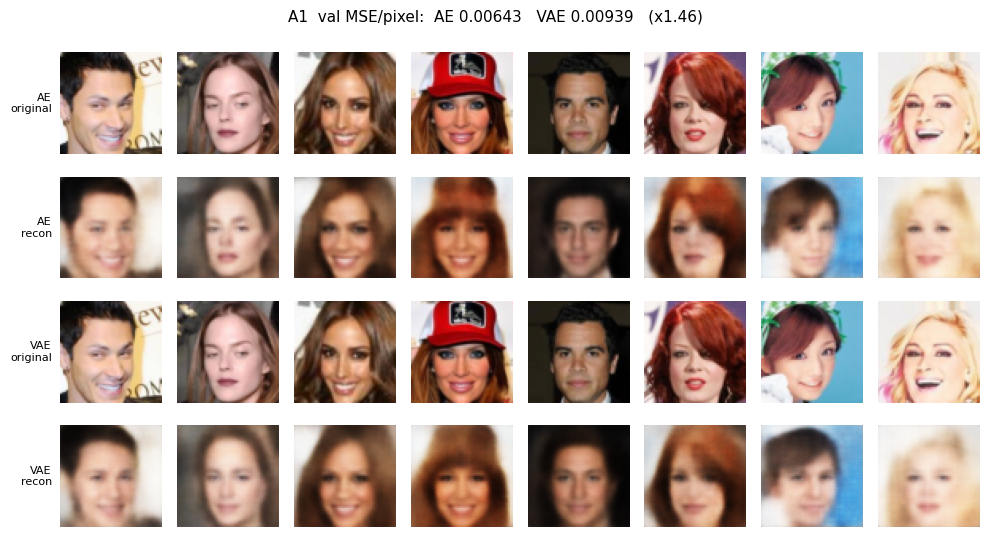

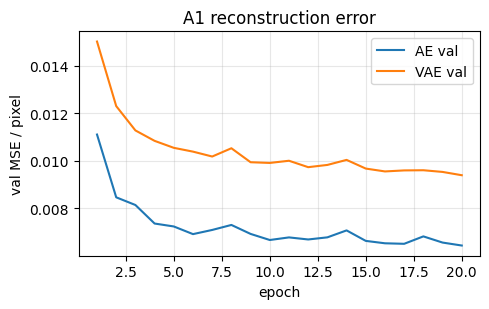

In [11]:
set_seed()
vis = torch.stack([celeba_va[i] for i in range(8)]).to(DEV)
ae.eval(); vae.eval()
with torch.no_grad():
    ae_rec, vae_rec = ae(vis)[0].cpu(), vae(vis)[0].cpu()

row_panel([vis.cpu(), ae_rec, vis.cpu(), vae_rec],
          ["AE\noriginal", "AE\nrecon", "VAE\noriginal", "VAE\nrecon"], ncol=8,
          title=(f"A1  val MSE/pixel:  AE {ae_hist[-1,3]:.5f}   VAE {vae_hist[-1,3]:.5f}"
                 f"   (x{vae_hist[-1,3]/ae_hist[-1,3]:.2f})"),
          save="figures/A1_recon.png")

plt.figure(figsize=(5, 3.2))
plt.plot(ae_hist[:, 0],  ae_hist[:, 3],  label="AE val")
plt.plot(vae_hist[:, 0], vae_hist[:, 3], label="VAE val")
plt.xlabel("epoch"); plt.ylabel("val MSE / pixel"); plt.legend(); plt.grid(alpha=.3)
plt.title("A1 reconstruction error"); plt.tight_layout()
plt.savefig("figures/A1_curves.png", dpi=140, bbox_inches="tight"); plt.show()

### A2 · What the VAE can do — interpolate

Interpolate the **means**, not samples from q. `pick_pair` matches the two endpoints on
Male and Young where it can, so the strip shows the attribute changing rather than the
identity changing. `frame_step_mse` is the frame-to-frame change: its largest entry is the
frame where the attribute jumps, which is the number A2 asks to point at.

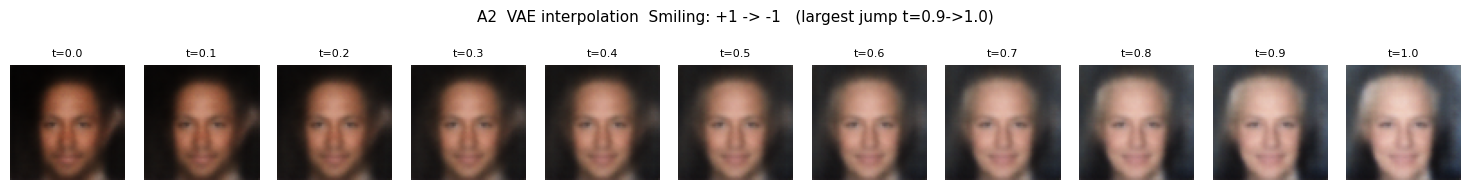

  A2_smiling_endpoints = [23360, 448]
  A2_smiling_frame_step_mse = [0.0006145625957287848, 0.0007143925759010017, 0.0008029669406823814, 0.0009196358732879162, 0.0010234075598418713, 0.0011004501720890403, 0.0011805506655946374, 0.0012304591946303844, 0.0013215071521699429, 0.0013655509101226926]
  A2_smiling_largest_jump_between_t = [0.9, 1.0]


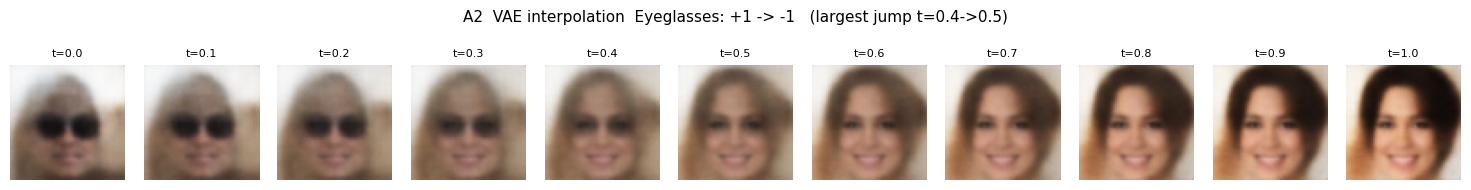

  A2_eyeglasses_endpoints = [6955, 2181]
  A2_eyeglasses_frame_step_mse = [0.0019173487089574337, 0.002196347340941429, 0.0023358657490462065, 0.00251214113086462, 0.002529017860069871, 0.0024907346814870834, 0.0022609401494264603, 0.0020405997056514025, 0.0018340182723477483, 0.0014730800176039338]
  A2_eyeglasses_largest_jump_between_t = [0.4, 0.5]


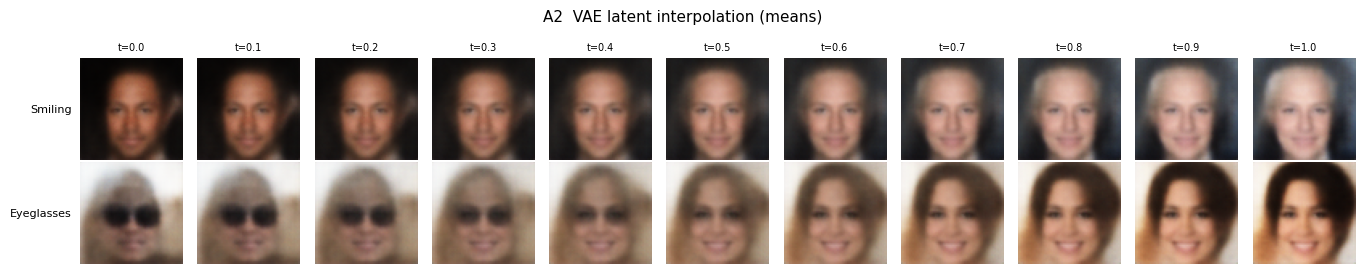

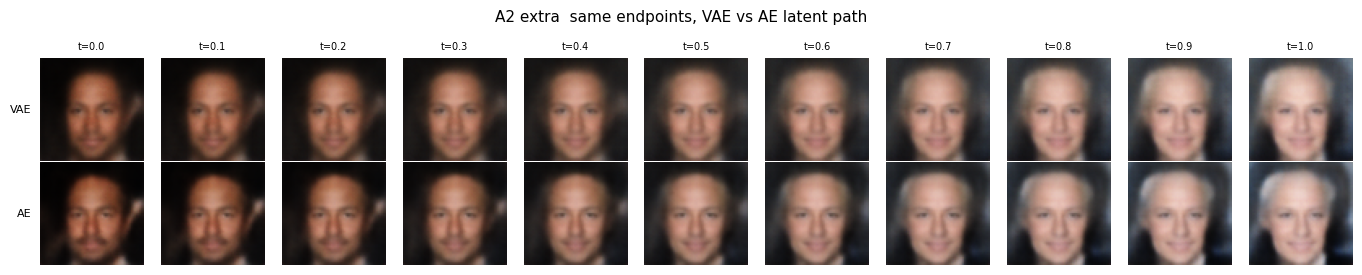

In [12]:
@torch.no_grad()
def interpolate(decode, z1, z2, n=11):
    """Decode n evenly spaced points on the straight line from z1 to z2."""
    t = torch.linspace(0, 1, n, device=z1.device).view(-1, 1)
    return decode((1 - t) * z1.view(1, -1) + t * z2.view(1, -1)), t.flatten().tolist()


rng = np.random.default_rng(SEED)

def pick_pair(attr_name, match_on=("Male", "Young")):
    """One image with the attribute, one without, matched on nuisance attributes where
    possible, so the strip shows the ATTRIBUTE changing rather than the identity."""
    pos, neg = np.where(celeba_attr[attr_name])[0], np.where(~celeba_attr[attr_name])[0]
    i = int(rng.choice(pos))
    mask = np.ones(len(neg), bool)
    for m in match_on:
        if m in celeba_attr: mask &= (celeba_attr[m][neg] == celeba_attr[m][i])
    j = int(rng.choice(neg[mask] if mask.sum() else neg))
    return i, j


@torch.no_grad()
def attr_strip(attr_name, tag):
    i, j = pick_pair(attr_name)
    x1 = (celeba_u8[i].float() / 255).unsqueeze(0).to(DEV)
    x2 = (celeba_u8[j].float() / 255).unsqueeze(0).to(DEV)
    mu1, mu2 = vae.encode(x1)[0][0], vae.encode(x2)[0][0]     # MEANS, not samples from q
    row, ts = interpolate(vae.dec, mu1, mu2, 11); row = row.cpu()
    step = ((row[1:] - row[:-1]) ** 2).flatten(1).mean(1).numpy()
    k = int(step.argmax())
    strip(row, labels=[f"t={t:.1f}" for t in ts],
          title=f"A2  VAE interpolation  {attr_name}: +1 -> -1   "
                f"(largest jump t={ts[k]:.1f}->{ts[k+1]:.1f})",
          save=f"figures/A2_vae_interp_{tag}.png")
    record(f"A2_{tag}_endpoints", [i, j])
    record(f"A2_{tag}_frame_step_mse", [float(s) for s in step])
    record(f"A2_{tag}_largest_jump_between_t", [round(ts[k], 1), round(ts[k + 1], 1)])
    return row, ts, step


row_sm, ts, step_sm = attr_strip("Smiling", "smiling")
row_at, _,  step_at = attr_strip(MY_ATTR, MY_ATTR.lower())

row_panel([row_sm, row_at], ["Smiling", MY_ATTR], ncol=11,
          col_labels=[f"t={t:.1f}" for t in ts],
          title="A2  VAE latent interpolation (means)", save="figures/A2_vae_interp.png")

# extra, not required: the same two endpoints through the AE's latent path
with torch.no_grad():
    i, j = METRICS["A2_smiling_endpoints"]
    z1 = ae.enc((celeba_u8[i].float() / 255).unsqueeze(0).to(DEV))[0]
    z2 = ae.enc((celeba_u8[j].float() / 255).unsqueeze(0).to(DEV))[0]
    ae_row, _ = interpolate(ae.dec, z1, z2, 11)

row_panel([row_sm, ae_row.cpu()], ["VAE", "AE"], ncol=11,
          col_labels=[f"t={t:.1f}" for t in ts],
          title="A2 extra  same endpoints, VAE vs AE latent path",
          save="figures/A2_extra_ae_interp.png")

### A3 · What the AE cannot do — generate

The same 16 codes go through both decoders. The third panel decodes codes from the AE's
**own** encoder, so the reader can see the decoder is not broken.

The second cell is the measurement that explains it: for a 64-d standard normal,
E‖z‖ ≈ √64 = 8. Compare that with where the AE actually puts its codes, and compare the
distance from a prior draw to the nearest AE code against the distance between AE codes
themselves.

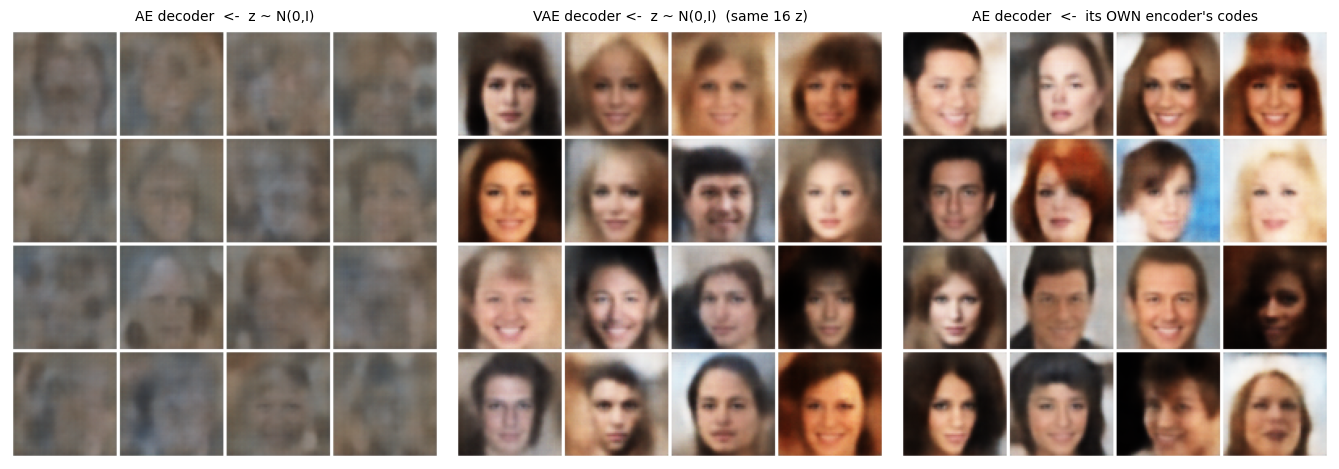

In [14]:
set_seed()
z_prior = torch.randn(16, LATENT, device=DEV)      # THE SAME 16 CODES FOR BOTH DECODERS

with torch.no_grad():
    ae_prior  = ae.dec(z_prior).cpu()
    vae_prior = vae.dec(z_prior).cpu()
    x16       = torch.stack([celeba_va[i] for i in range(16)]).to(DEV)
    ae_own    = ae.dec(ae.enc(x16)).cpu()          # decoder on codes it was trained on

fig, axs = plt.subplots(1, 3, figsize=(13.5, 5))
for ax, imgs, t in zip(axs, [ae_prior, vae_prior, ae_own],
                       ["AE decoder  <-  z ~ N(0,I)",
                        "VAE decoder <-  z ~ N(0,I)  (same 16 z)",
                        "AE decoder  <-  its OWN encoder's codes"]):
    g = torchvision.utils.make_grid(imgs.clamp(0, 1), nrow=4, padding=2, pad_value=1)
    ax.imshow(g.permute(1, 2, 0)); ax.axis("off"); ax.set_title(t, fontsize=10)
plt.tight_layout(); plt.savefig("figures/A3_prior_samples.png", dpi=140, bbox_inches="tight")
plt.show()

---
## 3 · Part B — denoising (MNIST)

*Still to be written — the cells below are the starter's.*

In [16]:
def psnr(a, b_, data_range=1.0):
    """a, b_: tensors in [0,1]. Returns mean PSNR in dB over the batch."""
    mse = ((a - b_) ** 2).flatten(1).mean(1).clamp_min(1e-12)
    return (10 * torch.log10(data_range ** 2 / mse)).mean().item()

class SmallAE(nn.Module):
    """28x28 -> LATENT_M -> 28x28. Small enough to train in a couple of minutes."""
    def __init__(self, d=32):
        super().__init__()
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(True), nn.Linear(256, d))
        self.dec = nn.Sequential(nn.Linear(d, 256), nn.ReLU(True), nn.Linear(256, 784),
                                 nn.Sigmoid(), nn.Unflatten(1, (1, 28, 28)))
    def forward(self, x):
        return self.dec(self.enc(x))



In [17]:
EPOCHS_B, BS_B, LR_B, SIGMA_B = 10, 256, 1e-3, 0.3

def add_noise(x, sigma=SIGMA_B):
    """x_tilde = clip(x + 0.3 * eps, 0, 1),  eps ~ N(0, I)."""
    return (x + sigma * torch.randn_like(x)).clamp(0, 1)


@torch.no_grad()
def eval_denoise(model, loader):
    """Mean test PSNR of (noisy vs clean) and (denoised vs clean).
    The noise uses a fixed generator, so every epoch sees the SAME corrupted test set."""
    model.eval()
    g = torch.Generator().manual_seed(SEED)
    pn, pd, n = 0.0, 0.0, 0
    for x, _ in loader:
        xn = (x + SIGMA_B * torch.randn(x.shape, generator=g)).clamp(0, 1)
        xh = model(xn.to(DEV)).cpu()
        b = len(x)
        pn += psnr(xn, x) * b; pd += psnr(xh, x) * b; n += b
    model.train()
    return pn / n, pd / n


def train_denoiser(epochs=EPOCHS_B):
    set_seed()
    model = SmallAE(d=32).to(DEV)
    opt   = torch.optim.Adam(model.parameters(), lr=LR_B)
    tl = DataLoader(mnist_tr, batch_size=BS_B, shuffle=True, drop_last=True, num_workers=2)
    te = DataLoader(mnist_te, batch_size=1000, shuffle=False)

    f = open("logs/B1_denoise_ae.csv", "w", newline="")
    w = csv.writer(f); w.writerow(["epoch", "train_mse", "test_psnr_noisy", "test_psnr_denoised"])
    for ep in range(1, epochs + 1):
        t0, run, nb = time.time(), 0.0, 0
        for x, _ in tl:
            x  = x.to(DEV, non_blocking=True)
            xn = add_noise(x)                      # noisy INPUT, clean TARGET
            loss = F.mse_loss(model(xn), x)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            run += loss.item(); nb += 1
        p_noisy, p_den = eval_denoise(model, te)
        w.writerow([ep, run / nb, p_noisy, p_den]); f.flush()
        print(f"[denoise] ep {ep:02d}/{epochs}  train_mse {run/nb:.5f}  "
              f"PSNR noisy {p_noisy:.2f} dB -> denoised {p_den:.2f} dB  ({time.time()-t0:.0f}s)")
    f.close(); torch.save(model.state_dict(), "ckpt/denoise_ae.pt")
    return model, p_noisy, p_den


dae, psnr_noisy, psnr_den = train_denoiser()
record("B1_psnr_noisy",    psnr_noisy)
record("B1_psnr_denoised", psnr_den)
record("B1_psnr_gain_db",  psnr_den - psnr_noisy)

[denoise] ep 01/10  train_mse 0.05994  PSNR noisy 13.32 dB -> denoised 15.02 dB  (5s)
[denoise] ep 02/10  train_mse 0.02790  PSNR noisy 13.32 dB -> denoised 16.87 dB  (5s)
[denoise] ep 03/10  train_mse 0.02119  PSNR noisy 13.32 dB -> denoised 17.74 dB  (5s)
[denoise] ep 04/10  train_mse 0.01793  PSNR noisy 13.32 dB -> denoised 18.36 dB  (5s)
[denoise] ep 05/10  train_mse 0.01599  PSNR noisy 13.32 dB -> denoised 18.79 dB  (5s)
[denoise] ep 06/10  train_mse 0.01469  PSNR noisy 13.32 dB -> denoised 19.09 dB  (5s)
[denoise] ep 07/10  train_mse 0.01382  PSNR noisy 13.32 dB -> denoised 19.34 dB  (5s)
[denoise] ep 08/10  train_mse 0.01316  PSNR noisy 13.32 dB -> denoised 19.48 dB  (5s)
[denoise] ep 09/10  train_mse 0.01267  PSNR noisy 13.32 dB -> denoised 19.65 dB  (5s)
[denoise] ep 10/10  train_mse 0.01225  PSNR noisy 13.32 dB -> denoised 19.80 dB  (5s)
  B1_psnr_noisy = 13.324507808685302
  B1_psnr_denoised = 19.796875381469725
  B1_psnr_gain_db = 6.472367572784423


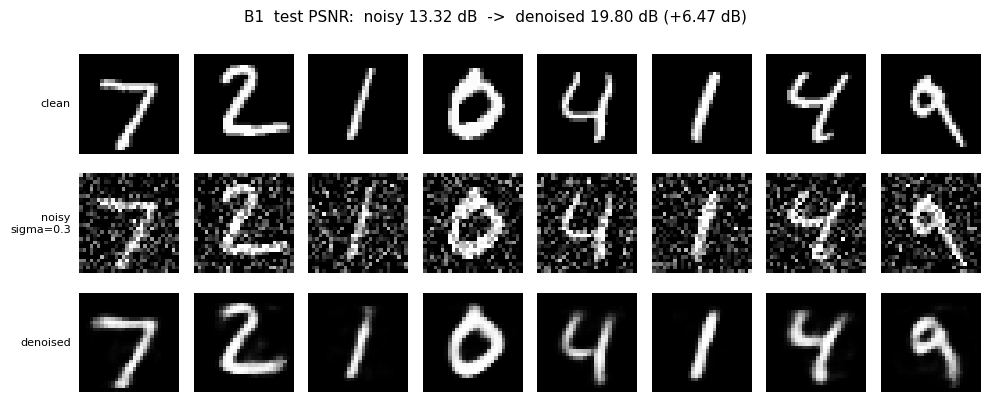

In [18]:
# three-row figure: clean / noisy / denoised
set_seed()
x_clean = torch.stack([mnist_te[i][0] for i in range(8)])
g = torch.Generator().manual_seed(SEED)
x_noisy = (x_clean + SIGMA_B * torch.randn(x_clean.shape, generator=g)).clamp(0, 1)
with torch.no_grad():
    dae.eval(); x_den = dae(x_noisy.to(DEV)).cpu()

row_panel([x_clean, x_noisy, x_den], ["clean", f"noisy\nsigma={SIGMA_B}", "denoised"], ncol=8,
          title=(f"B1  test PSNR:  noisy {psnr_noisy:.2f} dB  ->  denoised {psnr_den:.2f} dB "
                 f"(+{psnr_den - psnr_noisy:.2f} dB)"),
          save="figures/B1_denoise.png")

### B2 · The same AE as an anomaly detector

The held-out digit from §1.2 is 6. This AE is trained on MNIST with every 6 removed, so
digit 6 is off its manifold at test time and should reconstruct worse than anything it
has seen. ROC-AUC is computed from the rank statistic rather than imported.

[anomaly] ep 01/8  train_mse 0.05821
[anomaly] ep 02/8  train_mse 0.02274
[anomaly] ep 03/8  train_mse 0.01582
[anomaly] ep 04/8  train_mse 0.01290
[anomaly] ep 05/8  train_mse 0.01127
[anomaly] ep 06/8  train_mse 0.01020
[anomaly] ep 07/8  train_mse 0.00942
[anomaly] ep 08/8  train_mse 0.00885
  B2_held_out_digit = 6
  B2_mean_err_normal = 0.008372146636247635
  B2_mean_err_held_out = 0.01846448890864849
  B2_err_ratio = 2.2054665088653564
  B2_roc_auc = 0.8829552785216196
  B2_per_digit_mean_err = {'0': 0.0084486473351717, '1': 0.002508241217583418, '2': 0.011585472151637077, '3': 0.009333698078989983, '4': 0.008994131349027157, '5': 0.010434437543153763, '6': 0.01846448890864849, '7': 0.006449773907661438, '8': 0.011986440978944302, '9': 0.006686083506792784}


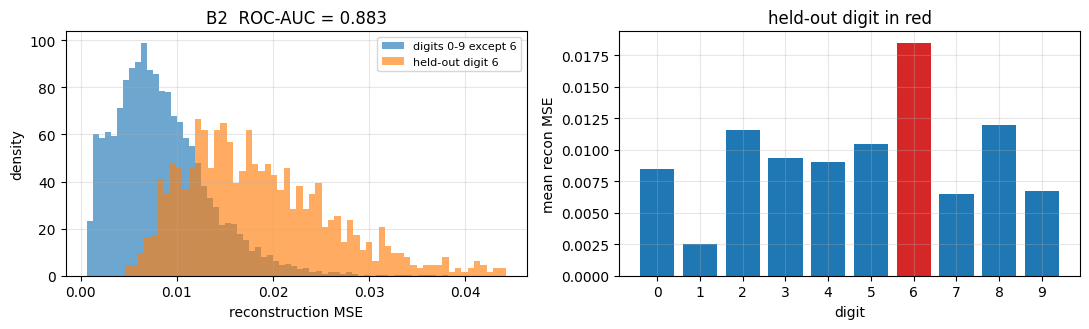

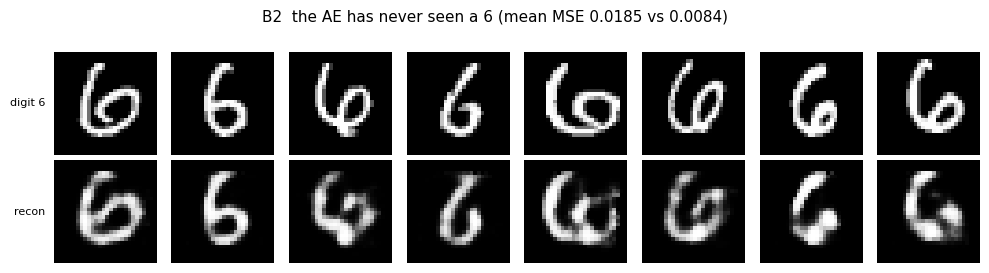

In [19]:
# ---- B2: the AE as an anomaly detector (held-out digit) ----
EPOCHS_B2 = 8

def auc_from_scores(scores, labels):
    """ROC-AUC via the Mann-Whitney rank statistic. labels: 1 = anomaly, 0 = normal.
    Equivalent to P(score of a random anomaly > score of a random normal)."""
    from scipy.stats import rankdata
    r   = rankdata(scores)                      # average ranks, so ties are handled
    pos = (labels == 1)
    n_p, n_n = int(pos.sum()), int((~pos).sum())
    return float((r[pos].sum() - n_p * (n_p + 1) / 2) / (n_p * n_n))


@torch.no_grad()
def recon_errors(model, ds, bs=1000):
    """Per-image reconstruction MSE, plus the true labels."""
    model.eval(); E, Y = [], []
    for x, y in DataLoader(ds, batch_size=bs):
        x = x.to(DEV)
        E.append(((model(x) - x) ** 2).flatten(1).mean(1).cpu()); Y.append(y)
    model.train()
    return torch.cat(E).numpy(), torch.cat(Y).numpy()


def train_anomaly_ae(epochs=EPOCHS_B2):
    set_seed()
    model = SmallAE(d=32).to(DEV)
    opt   = torch.optim.Adam(model.parameters(), lr=LR_B)
    tl = DataLoader(exclude_digit(mnist_tr, HELD_OUT_DIGIT),      # never sees the digit
                    batch_size=BS_B, shuffle=True, drop_last=True, num_workers=2)
    f = open("logs/B2_anomaly_ae.csv", "w", newline="")
    w = csv.writer(f); w.writerow(["epoch", "train_mse"])
    for ep in range(1, epochs + 1):
        run, nb = 0.0, 0
        for x, _ in tl:
            x = x.to(DEV, non_blocking=True)
            loss = F.mse_loss(model(x), x)                        # clean in, clean out
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            run += loss.item(); nb += 1
        w.writerow([ep, run / nb]); f.flush()
        print(f"[anomaly] ep {ep:02d}/{epochs}  train_mse {run/nb:.5f}")
    f.close(); torch.save(model.state_dict(), "ckpt/anomaly_ae.pt")
    return model


ae_anom = train_anomaly_ae()
err, ytrue = recon_errors(ae_anom, mnist_te)
is_held = (ytrue == HELD_OUT_DIGIT).astype(int)

auc = auc_from_scores(err, is_held)
record("B2_held_out_digit", HELD_OUT_DIGIT)
record("B2_mean_err_normal",   float(err[is_held == 0].mean()))
record("B2_mean_err_held_out", float(err[is_held == 1].mean()))
record("B2_err_ratio",         float(err[is_held == 1].mean() / err[is_held == 0].mean()))
record("B2_roc_auc",           auc)
record("B2_per_digit_mean_err", {str(d): float(err[ytrue == d].mean()) for d in range(10)})

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
axs[0].hist(err[is_held == 0], bins=60, alpha=.65, density=True, label="digits 0-9 except 6")
axs[0].hist(err[is_held == 1], bins=60, alpha=.65, density=True, label=f"held-out digit {HELD_OUT_DIGIT}")
axs[0].set_xlabel("reconstruction MSE"); axs[0].set_ylabel("density")
axs[0].set_title(f"B2  ROC-AUC = {auc:.3f}"); axs[0].legend(fontsize=8); axs[0].grid(alpha=.3)
per_d = [err[ytrue == d].mean() for d in range(10)]
axs[1].bar(range(10), per_d, color=["tab:red" if d == HELD_OUT_DIGIT else "tab:blue" for d in range(10)])
axs[1].set_xticks(range(10)); axs[1].set_xlabel("digit"); axs[1].set_ylabel("mean recon MSE")
axs[1].set_title("held-out digit in red"); axs[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("figures/B2_anomaly.png", dpi=140, bbox_inches="tight"); plt.show()

# what the held-out digit looks like after a round trip through an AE that never saw it
idx6 = np.where(ytrue == HELD_OUT_DIGIT)[0][:8]
x6   = torch.stack([mnist_te[int(i)][0] for i in idx6]).to(DEV)
with torch.no_grad():
    ae_anom.eval(); r6 = ae_anom(x6).cpu()
row_panel([x6.cpu(), r6], [f"digit {HELD_OUT_DIGIT}", "recon"], ncol=8,
          title=f"B2  the AE has never seen a {HELD_OUT_DIGIT} "
                f"(mean MSE {err[is_held==1].mean():.4f} vs {err[is_held==0].mean():.4f})",
          save="figures/B2_anomaly_recons.png")

---
## 4 · Parts C–D — GANs on your six digits

`GAN_SHAPES` below is a working DCGAN for 28×28. Part C1 deliberately breaks it; Part D
puts it back together. *Still to be written.*

In [20]:
ZDIM = 64

class G28(nn.Module):
    """z -> 7x7 -> 14x14 -> 28x28. Set batchnorm=False for the Part C3 collapse recipe."""
    def __init__(self, zdim=ZDIM, ch=128, batchnorm=True):
        super().__init__()
        def bn(c): return nn.BatchNorm2d(c) if batchnorm else nn.Identity()
        self.fc = nn.Sequential(nn.Linear(zdim, ch * 7 * 7), nn.Unflatten(1, (ch, 7, 7)),
                                bn(ch), nn.ReLU(True))
        self.body = nn.Sequential(
            nn.ConvTranspose2d(ch, ch // 2, 4, 2, 1), bn(ch // 2), nn.ReLU(True),   # 14
            nn.ConvTranspose2d(ch // 2, 1, 4, 2, 1), nn.Tanh(),                     # 28
        )
    def forward(self, z): return self.body(self.fc(z))


class D28(nn.Module):
    def __init__(self, ch=64, spectral=False):
        super().__init__()
        w = (lambda m: nn.utils.spectral_norm(m)) if spectral else (lambda m: m)
        self.body = nn.Sequential(
            w(nn.Conv2d(1, ch, 4, 2, 1)), nn.LeakyReLU(0.2, True),                 # 14
            w(nn.Conv2d(ch, ch * 2, 4, 2, 1)), nn.LeakyReLU(0.2, True),            # 7
            nn.Flatten(), w(nn.Linear(ch * 2 * 7 * 7, 1)),
        )
    def forward(self, x): return self.body(x)      # LOGITS -- apply sigmoid yourself


def to_pm1(x): return x * 2 - 1        # MNIST arrives in [0,1]; G outputs tanh
def to_01(x):  return (x + 1) / 2

In [21]:
ITERS_C, BS_C, SNAP_EVERY = 3000, 128, 50

def infinite(loader):
    while True:
        for b in loader: yield b


def train_gan_c(loss_kind, tag, iters=ITERS_C, d_steps=5, lr_d=8e-4, lr_g=2e-4,
                zdim=ZDIM, batchnorm_g=True, g_steps=1):
    """Returns (log_array, fixed-noise snapshots, G, D). The RunLog hook writes one CSV
    row per iteration -- that file is where C1's answer lives."""
    set_seed()
    G = G28(zdim=zdim, batchnorm=batchnorm_g).to(DEV)
    D = D28().to(DEV)
    optG = torch.optim.Adam(G.parameters(), lr=lr_g, betas=(0.5, 0.999))
    optD = torch.optim.Adam(D.parameters(), lr=lr_d, betas=(0.5, 0.999))
    loader = DataLoader(mnist_mine, batch_size=BS_C, shuffle=True, drop_last=True,
                        num_workers=2)
    stream = infinite(loader)
    log = RunLog(tag)                                  # <-- do not remove
    fixed_z, snaps = torch.randn(64, zdim, device=DEV), {}
    bce = F.binary_cross_entropy_with_logits
    t0 = time.time()

    for it in range(1, iters + 1):
        # ---- D steps ----
        for _ in range(d_steps):
            x, _ = next(stream)
            x = to_pm1(x.to(DEV, non_blocking=True))
            z = torch.randn(len(x), zdim, device=DEV)
            with torch.no_grad(): fake = G(z)
            dr, df = D(x), D(fake)
            d_loss = bce(dr, torch.ones_like(dr)) + bce(df, torch.zeros_like(df))
            optD.zero_grad(set_to_none=True); d_loss.backward(); optD.step()
        D_x, D_G_z = torch.sigmoid(dr).mean().item(), torch.sigmoid(df).mean().item()

        # ---- G step(s) ----
        for _ in range(g_steps):
            z = torch.randn(BS_C, zdim, device=DEV)
            d_fake = D(G(z))
            if loss_kind == "saturating":
                g_loss = F.logsigmoid(-d_fake).mean()      # L_G = log(1 - D(G(z)))
            elif loss_kind == "nonsaturating":
                g_loss = -F.logsigmoid(d_fake).mean()      # L_G = -log D(G(z))
            else:
                raise ValueError(loss_kind)
            optG.zero_grad(set_to_none=True); g_loss.backward()
            gn = grad_norm(G.fc)                           # FIRST layer of the generator
            optG.step()

        log(it, d_loss.item(), g_loss.item(), D_x, D_G_z, gn)

        if it == 1 or it % SNAP_EVERY == 0 or it == iters:
            G.eval()
            with torch.no_grad(): snaps[it] = G(fixed_z).cpu()
            G.train()
        if it % 250 == 0:
            print(f"[{tag}] it {it:5d}/{iters}  d_loss {d_loss.item():.3f}  "
                  f"g_loss {g_loss.item():.3f}  D(x) {D_x:.3f}  D(G(z)) {D_G_z:.4f}  "
                  f"|grad_G| {gn:.3e}  ({time.time()-t0:.0f}s)")

    arr = log.close()
    torch.save(G.state_dict(), f"ckpt/{tag}_G.pt")
    torch.save(D.state_dict(), f"ckpt/{tag}_D.pt")
    return arr, snaps, G, D


def collapse_iteration_smoothed(arr, frac=0.01, ref_iter=100, win=51):
    """Same rule as the starter's collapse_iteration, but on a rolling median of the
    gradient norm -- a sanity check that the answer is not one noisy dip."""
    gn, k = arr[:, 5], win // 2
    sm = np.array([np.median(gn[max(0, i - k):i + k + 1]) for i in range(len(gn))])
    tmp = arr.copy(); tmp[:, 5] = sm
    return collapse_iteration(tmp, frac, ref_iter)


def snap_at(snaps, it):
    """Nearest fixed-noise snapshot at or after iteration `it`."""
    if it is None: return None, None
    keys = sorted(snaps)
    k = min([s for s in keys if s >= it], default=keys[-1])
    return snaps[k], k

In [22]:
# ---------------- C1: the SATURATING loss, D deliberately too strong ----------------
arr_c1, snaps_c1, G_c1, D_c1 = train_gan_c("saturating", "C1_saturating")

it_dead, ref = collapse_iteration(arr_c1)
it_dead_sm, ref_sm = collapse_iteration_smoothed(arr_c1)
record("C1_ref_gradnorm_at_100", ref)
record("C1_iteration_gradient_died", it_dead)
record("C1_threshold_1pct_of_ref", 0.01 * ref)
record("C1_iteration_gradient_died_smoothed", it_dead_sm)
record("C1_final_D_x",   float(arr_c1[-1, 3]))
record("C1_final_D_G_z", float(arr_c1[-1, 4]))
if it_dead is not None:
    j = int(np.where(arr_c1[:, 0] == it_dead)[0][0])
    record("C1_gradnorm_at_death", float(arr_c1[j, 5]))
    record("C1_D_G_z_at_death",    float(arr_c1[j, 4]))
    print(f"\ngradient norm was {ref:.4e} at iteration 100, "
          f"first fell below 1% of that ({0.01 * ref:.4e}) at iteration {it_dead}")
else:
    print("\nthe gradient never fell below 1% of its iteration-100 value")

# Supplementary, and the one to quote if the gradient had ALREADY collapsed by iteration
# 100: measure the decay from its peak over the first 200 iterations instead.
pj   = int(np.argmax(arr_c1[:200, 5]))
peak = float(arr_c1[pj, 5])
bel  = np.where((arr_c1[:, 0] > arr_c1[pj, 0]) & (arr_c1[:, 5] < 0.01 * peak))[0]
it_peak_death = int(arr_c1[bel[0], 0]) if len(bel) else None
record("C1_peak_gradnorm_first200", peak)
record("C1_peak_iteration", int(arr_c1[pj, 0]))
record("C1_iteration_below_1pct_of_peak", it_peak_death)

it_mark = it_dead if it_dead is not None else it_peak_death
print(f"peak |grad_G| {peak:.4e} at iteration {int(arr_c1[pj, 0])}, "
      f"below 1% of peak at iteration {it_peak_death}")

[C1_saturating] it   250/3000  d_loss 0.000  g_loss -0.000  D(x) 1.000  D(G(z)) 0.0000  |grad_G| 6.673e-06  (15s)
[C1_saturating] it   500/3000  d_loss 0.000  g_loss -0.000  D(x) 1.000  D(G(z)) 0.0000  |grad_G| 1.826e-07  (29s)
[C1_saturating] it   750/3000  d_loss 0.000  g_loss -0.000  D(x) 1.000  D(G(z)) 0.0000  |grad_G| 3.599e-07  (44s)
[C1_saturating] it  1000/3000  d_loss 0.000  g_loss -0.000  D(x) 1.000  D(G(z)) 0.0000  |grad_G| 9.867e-08  (58s)
[C1_saturating] it  1250/3000  d_loss 0.000  g_loss -0.000  D(x) 1.000  D(G(z)) 0.0000  |grad_G| 3.862e-07  (73s)
[C1_saturating] it  3000/3000  d_loss 0.000  g_loss -0.000  D(x) 1.000  D(G(z)) 0.0000  |grad_G| 2.011e-10  (178s)
  C1_ref_gradnorm_at_100 = 6.280490197241306e-05
  C1_iteration_gradient_died = 345
  C1_threshold_1pct_of_ref = 6.280490197241307e-07
  C1_iteration_gradient_died_smoothed = 761
  C1_final_D_x = 1.0
  C1_final_D_G_z = 9.804677902902625e-11
  C1_gradnorm_at_death = 4.703024103491771e-07
  C1_D_G_z_at_death = 2.260

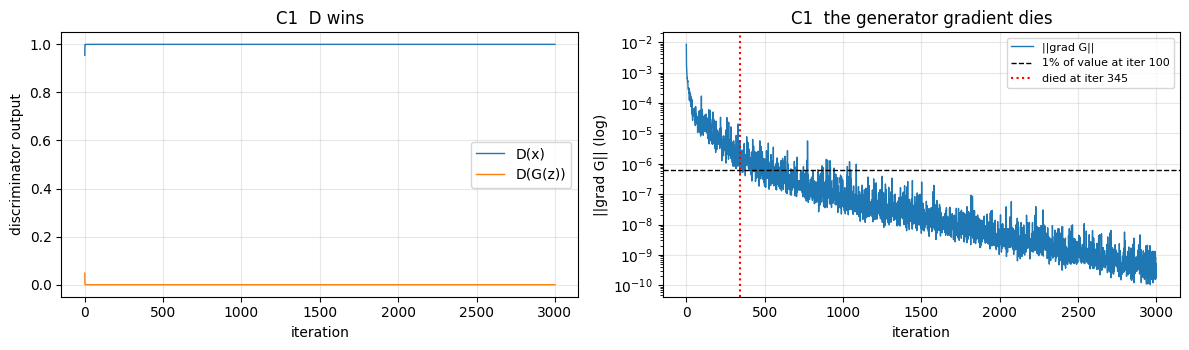

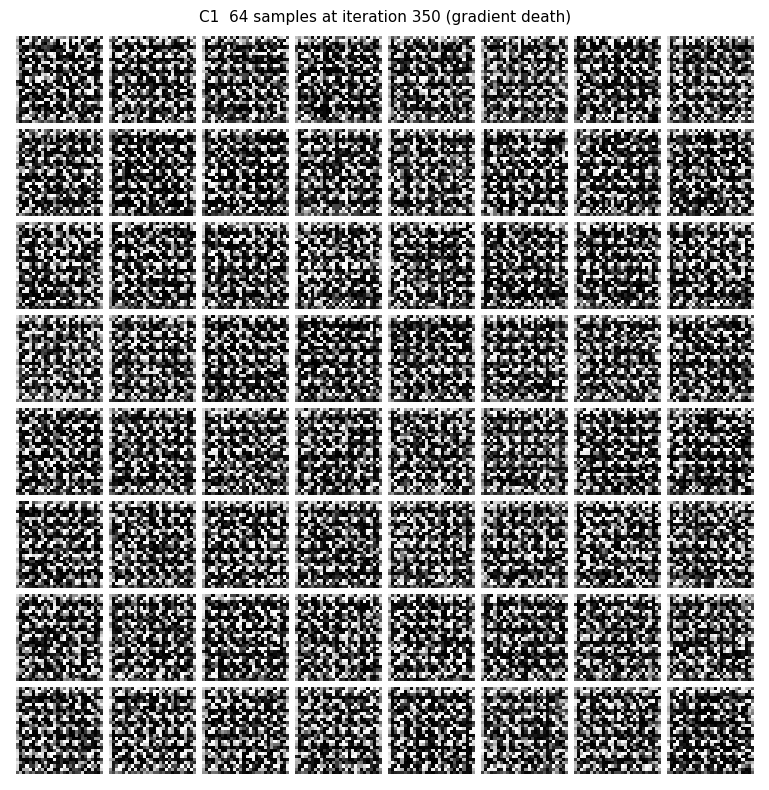

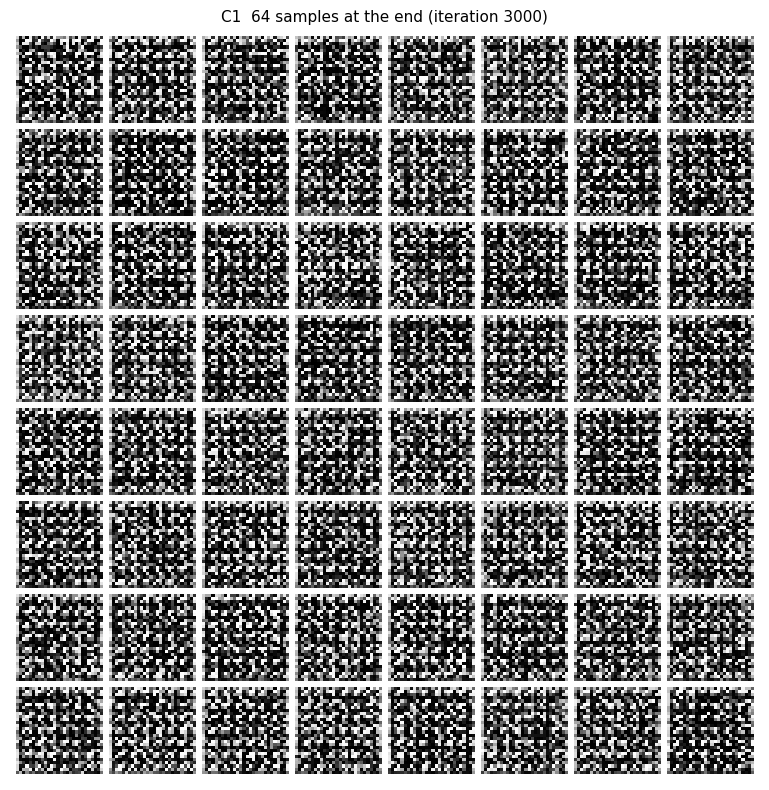

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(arr_c1[:, 0], arr_c1[:, 3], label="D(x)", lw=1)
ax[0].plot(arr_c1[:, 0], arr_c1[:, 4], label="D(G(z))", lw=1)
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("discriminator output")
ax[0].set_title("C1  D wins"); ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].semilogy(arr_c1[:, 0], np.maximum(arr_c1[:, 5], 1e-12), lw=1, label="||grad G||")
ax[1].axhline(0.01 * ref, ls="--", c="k", lw=1, label="1% of value at iter 100")
if it_mark is not None:
    ax[1].axvline(it_mark, ls=":", c="r", lw=1.5, label=f"died at iter {it_mark}")
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("||grad G|| (log)")
ax[1].set_title("C1  the generator gradient dies"); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("figures/C1_gradnorm.png", dpi=140, bbox_inches="tight"); plt.show()

s_death, k_death = snap_at(snaps_c1, it_mark)
if s_death is not None:
    show_grid(to_01(s_death), nrow=8, figsize=(8, 8),
              title=f"C1  64 samples at iteration {k_death} (gradient death)",
              save="figures/C1_samples_at_death.png")
show_grid(to_01(snaps_c1[max(snaps_c1)]), nrow=8, figsize=(8, 8),
          title=f"C1  64 samples at the end (iteration {max(snaps_c1)})",
          save="figures/C1_samples_end.png")

In [25]:
# ---------------- C2: identical run, ONE line changed ----------------
arr_c2, snaps_c2, G_c2, D_c2 = train_gan_c("nonsaturating", "C2_nonsaturating")

it_dead2, ref2 = collapse_iteration(arr_c2)
record("C2_ref_gradnorm_at_100", ref2)
record("C2_iteration_gradient_died", it_dead2)
record("C2_final_D_x",   float(arr_c2[-1, 3]))
record("C2_final_D_G_z", float(arr_c2[-1, 4]))
record("C2_median_gradnorm_last500", float(np.median(arr_c2[-500:, 5])))
record("C1_median_gradnorm_last500", float(np.median(arr_c1[-500:, 5])))

[C2_nonsaturating] it   250/3000  d_loss 0.025  g_loss 7.566  D(x) 0.987  D(G(z)) 0.0104  |grad_G| 2.203e+00  (15s)
[C2_nonsaturating] it   500/3000  d_loss 0.190  g_loss 3.556  D(x) 0.898  D(G(z)) 0.0362  |grad_G| 2.550e+00  (29s)
[C2_nonsaturating] it   750/3000  d_loss 0.226  g_loss 3.883  D(x) 0.887  D(G(z)) 0.0101  |grad_G| 3.017e+00  (44s)
[C2_nonsaturating] it  1000/3000  d_loss 0.228  g_loss 3.631  D(x) 0.913  D(G(z)) 0.0388  |grad_G| 2.553e+00  (58s)
[C2_nonsaturating] it  1250/3000  d_loss 0.219  g_loss 3.843  D(x) 0.938  D(G(z)) 0.0971  |grad_G| 2.383e+00  (73s)
[C2_nonsaturating] it  1500/3000  d_loss 0.205  g_loss 4.139  D(x) 0.931  D(G(z)) 0.0319  |grad_G| 2.492e+00  (88s)
[C2_nonsaturating] it  1750/3000  d_loss 0.188  g_loss 3.841  D(x) 0.955  D(G(z)) 0.1042  |grad_G| 2.783e+00  (102s)
[C2_nonsaturating] it  2000/3000  d_loss 0.337  g_loss 2.398  D(x) 0.883  D(G(z)) 0.0589  |grad_G| 2.571e+00  (117s)
[C2_nonsaturating] it  2250/3000  d_loss 0.203  g_loss 4.101  D(x) 0.9

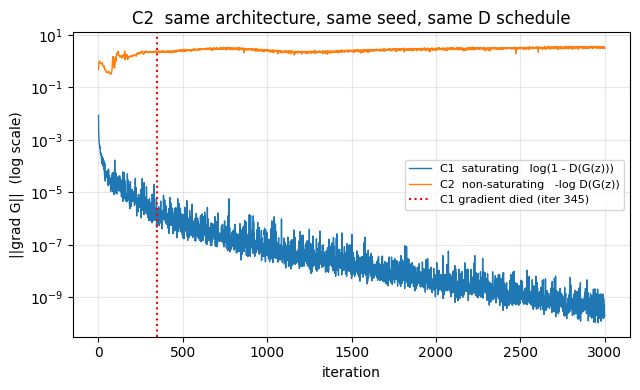

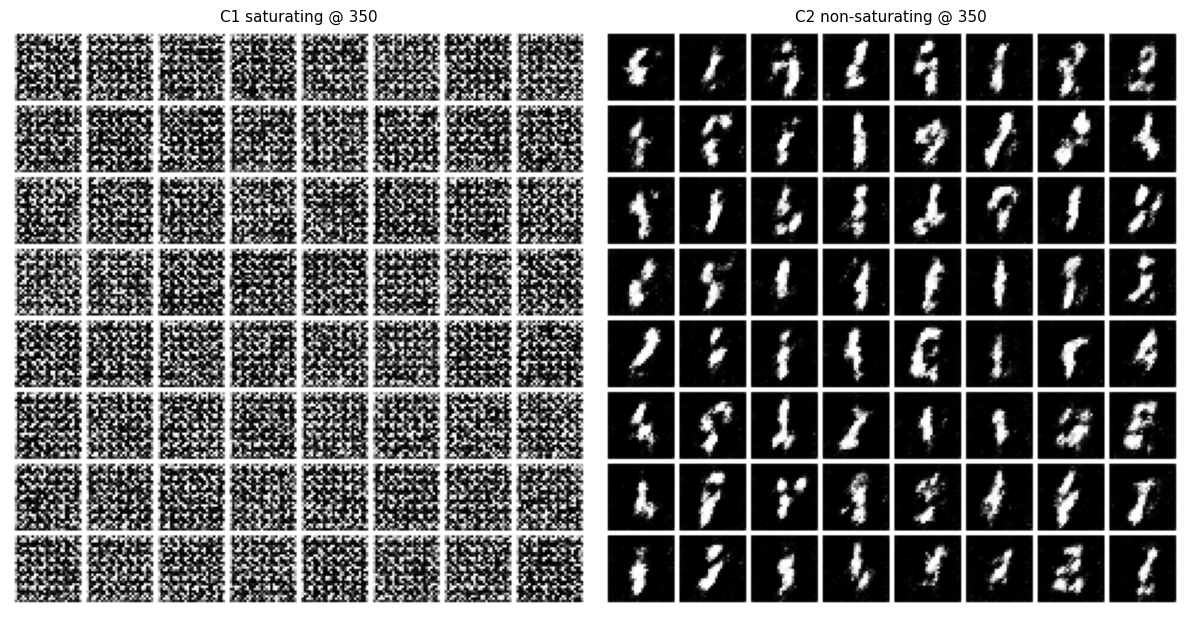

In [26]:
plt.figure(figsize=(6.5, 4))
plt.semilogy(arr_c1[:, 0], np.maximum(arr_c1[:, 5], 1e-12), lw=1,
             label="C1  saturating   log(1 - D(G(z)))")
plt.semilogy(arr_c2[:, 0], np.maximum(arr_c2[:, 5], 1e-12), lw=1,
             label="C2  non-saturating   -log D(G(z))")
if it_mark is not None:
    plt.axvline(it_mark, ls=":", c="r", lw=1.5, label=f"C1 gradient died (iter {it_mark})")
plt.xlabel("iteration"); plt.ylabel("||grad G||  (log scale)")
plt.title("C2  same architecture, same seed, same D schedule")
plt.legend(fontsize=8); plt.grid(alpha=.3, which="both"); plt.tight_layout()
plt.savefig("figures/C2_overlay.png", dpi=140, bbox_inches="tight"); plt.show()

# the two sample grids at the SAME iteration, side by side
cmp_it = it_mark if it_mark is not None else max(snaps_c1)
s1, k1 = snap_at(snaps_c1, cmp_it)
s2, k2 = snap_at(snaps_c2, cmp_it)
fig, axs = plt.subplots(1, 2, figsize=(12, 6.2))
for ax, s, t in zip(axs, [s1, s2], [f"C1 saturating @ {k1}", f"C2 non-saturating @ {k2}"]):
    g = torchvision.utils.make_grid(to_01(s).clamp(0, 1), nrow=8, padding=2, pad_value=1)
    ax.imshow(g.permute(1, 2, 0).squeeze(), cmap="gray"); ax.axis("off"); ax.set_title(t, fontsize=11)
plt.tight_layout(); plt.savefig("figures/C2_grids.png", dpi=140, bbox_inches="tight"); plt.show()

### 4.1 · The classifier — you need it for mode counting, IS and FID

In [27]:
class MnistCNN(nn.Module):
    """Trains to ~99% on a six-digit subset in about a minute.
    `features()` gives the 128-d penultimate vector -- that is your FID feature space."""
    def __init__(self, n_classes):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, 1, 1), nn.ReLU(True), nn.MaxPool2d(2),   # 14
            nn.Conv2d(32, 64, 3, 1, 1), nn.ReLU(True), nn.MaxPool2d(2),  # 7
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(True))
        self.head = nn.Linear(128, n_classes)
    def features(self, x): return self.conv(x)
    def forward(self, x):  return self.head(self.conv(x))



In [28]:
# labels 1,2,5,6,8,9  ->  0..5   (lookup table, so it works on a whole batch at once)
LUT = torch.full((10,), -1, dtype=torch.long)
for i, d in enumerate(MY_DIGITS): LUT[d] = i

mnist_mine_te = subset_by_digits(mnist_te, MY_DIGITS)

def train_classifier(epochs=3, bs=256, lr=1e-3):
    set_seed()
    clf = MnistCNN(len(MY_DIGITS)).to(DEV)
    opt = torch.optim.Adam(clf.parameters(), lr=lr)
    tl = DataLoader(mnist_mine,    batch_size=bs, shuffle=True, num_workers=2, drop_last=True)
    te = DataLoader(mnist_mine_te, batch_size=1000, shuffle=False)
    for ep in range(1, epochs + 1):
        for x, y in tl:
            x, y = x.to(DEV), LUT[y].to(DEV)
            loss = F.cross_entropy(clf(x), y)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        clf.eval(); correct = tot = 0
        with torch.no_grad():
            for x, y in te:
                pred = clf(x.to(DEV)).argmax(1).cpu()
                correct += (pred == LUT[y]).sum().item(); tot += len(y)
        clf.train()
        print(f"[clf] epoch {ep}  test acc {correct/tot:.4f}")
    torch.save(clf.state_dict(), "ckpt/clf.pt")
    return clf, correct / tot


clf, clf_acc = train_classifier()
clf.eval()
record("C3_classifier_test_acc", clf_acc)
if clf_acc <= 0.97:
    print(f"WARNING: classifier only {clf_acc:.4f} -- metrics below depend on it")

[clf] epoch 1  test acc 0.9770
[clf] epoch 2  test acc 0.9900
[clf] epoch 3  test acc 0.9895
  C3_classifier_test_acc = 0.9895


In [29]:
@torch.no_grad()
def classify(clf, imgs, bs=500):
    """imgs in [0,1], (N,1,28,28). Returns (probs (N,K), features (N,128))."""
    P, Fe = [], []
    for i in range(0, len(imgs), bs):
        xb = imgs[i:i+bs].to(DEV)
        f = clf.features(xb); p = clf.head(f).softmax(1)
        P.append(p.cpu()); Fe.append(f.cpu())
    return torch.cat(P).numpy(), torch.cat(Fe).numpy()


def mode_stats(probs, k=6, tol=0.01):
    """Part C3 / D. probs: (N,K) softmax over your six digits.
    Returns (histogram, modes_covered, reverse_KL to the uniform target)."""
    pred = probs.argmax(1)
    hist = np.bincount(pred, minlength=k).astype(float)
    p_gen = hist / hist.sum()
    modes = int((p_gen >= tol).sum())
    q = np.full(k, 1 / k)                                  # uniform target
    m = p_gen > 0
    rev_kl = float((p_gen[m] * np.log(p_gen[m] / q[m])).sum())   # D_KL(p_gen || p_data)
    return p_gen, modes, rev_kl

### 4.2 · A general GAN loop, plus the measurement

`train_gan` is the same loop as `train_gan_c` with two extra knobs: a discriminator
factory (so D2 can swap in minibatch discrimination) and an arbitrary D:G step ratio.
`measure_model` is the C3 measurement — histogram, modes covered, reverse KL — and it is
re-used unchanged for D1 and D2, which is what makes the three rows of the D2 table
comparable.

In [30]:
def train_gan(tag, D_factory=lambda: D28(), zdim=ZDIM, batchnorm_g=True,
              d_steps=1, g_steps=1, lr_d=2e-4, lr_g=2e-4, iters=4000, bs=128,
              loss_kind="nonsaturating", snap_every=100):
    """Non-saturating loss throughout (C1 already showed why). Returns (log, snaps, G, D)."""
    set_seed()
    G = G28(zdim=zdim, batchnorm=batchnorm_g).to(DEV)
    D = D_factory().to(DEV)
    optG = torch.optim.Adam(G.parameters(), lr=lr_g, betas=(0.5, 0.999))
    optD = torch.optim.Adam(D.parameters(), lr=lr_d, betas=(0.5, 0.999))
    stream = infinite(DataLoader(mnist_mine, batch_size=bs, shuffle=True,
                                 drop_last=True, num_workers=2))
    log = RunLog(tag)                                   # <-- do not remove
    fixed_z, snaps = torch.randn(64, zdim, device=DEV), {}
    bce = F.binary_cross_entropy_with_logits
    t0 = time.time()

    for it in range(1, iters + 1):
        for _ in range(d_steps):
            x, _ = next(stream)
            x = to_pm1(x.to(DEV, non_blocking=True))
            z = torch.randn(len(x), zdim, device=DEV)
            with torch.no_grad(): fake = G(z)
            dr, df = D(x), D(fake)
            d_loss = bce(dr, torch.ones_like(dr)) + bce(df, torch.zeros_like(df))
            optD.zero_grad(set_to_none=True); d_loss.backward(); optD.step()
        D_x, D_G_z = torch.sigmoid(dr).mean().item(), torch.sigmoid(df).mean().item()

        for _ in range(g_steps):
            z = torch.randn(bs, zdim, device=DEV)
            d_fake = D(G(z))
            g_loss = (-F.logsigmoid(d_fake).mean() if loss_kind == "nonsaturating"
                      else F.logsigmoid(-d_fake).mean())
            optG.zero_grad(set_to_none=True); g_loss.backward()
            gn = grad_norm(G.fc)
            optG.step()

        log(it, d_loss.item(), g_loss.item(), D_x, D_G_z, gn)
        if it == 1 or it % snap_every == 0 or it == iters:
            G.eval()
            with torch.no_grad(): snaps[it] = G(fixed_z).cpu()
            G.train()
        if it % 500 == 0:
            print(f"[{tag}] it {it:5d}/{iters}  d_loss {d_loss.item():.3f}  "
                  f"g_loss {g_loss.item():.3f}  D(x) {D_x:.3f}  D(G(z)) {D_G_z:.3f}  "
                  f"({time.time()-t0:.0f}s)")

    arr = log.close()
    torch.save(G.state_dict(), f"ckpt/{tag}_G.pt")
    return arr, snaps, G, D


@torch.no_grad()
def sample_images(G, n=5000, zdim=ZDIM, bs=500):
    """n generated images in [0,1], shape (n,1,28,28) -- the format `classify` wants."""
    G.eval(); out = []
    for i in range(0, n, bs):
        z = torch.randn(min(bs, n - i), zdim, device=DEV)
        out.append(to_01(G(z)).clamp(0, 1).cpu())
    G.train()
    return torch.cat(out)


GEN = {}          # tag -> dict(images, probs, feats, p_gen, modes, rev_kl)

def measure_model(G, tag, zdim=ZDIM, n=5000):
    """C3's measurement, re-used for D1 and D2. Also caches features for Part E."""
    imgs = sample_images(G, n, zdim)
    probs, feats = classify(clf, imgs)
    p_gen, modes, rev_kl = mode_stats(probs, k=len(MY_DIGITS))
    div = float(imgs.std(0).mean())          # pixel-wise spread across samples
    record(f"{tag}_modes_covered", modes)
    record(f"{tag}_reverse_kl", rev_kl)
    record(f"{tag}_histogram", [float(v) for v in p_gen])
    record(f"{tag}_sample_diversity_std", div)

    plt.figure(figsize=(5, 3))
    plt.bar([str(d) for d in MY_DIGITS], p_gen, color="tab:blue")
    plt.axhline(1 / len(MY_DIGITS), ls="--", c="k", lw=1, label="uniform target")
    plt.ylabel("fraction of 5000 samples"); plt.xlabel("digit")
    plt.title(f"{tag}  modes covered {modes}/{len(MY_DIGITS)}   reverse-KL {rev_kl:.3f}")
    plt.legend(fontsize=8); plt.tight_layout()
    plt.savefig(f"figures/{tag}_hist.png", dpi=140, bbox_inches="tight"); plt.show()

    show_grid(imgs[:64], nrow=8, figsize=(8, 8), title=f"{tag}  64 samples",
              save=f"figures/{tag}_samples.png")
    GEN[tag] = dict(images=imgs, probs=probs, feats=feats,
                    p_gen=p_gen, modes=modes, rev_kl=rev_kl)
    print(f"{tag}: modes {modes}/{len(MY_DIGITS)}  reverse-KL {rev_kl:.4f}  "
          f"diversity {div:.4f}")
    return GEN[tag]

### C3 · Force a collapse, then measure it

recipe: z-dim 2, no BatchNorm in G, **five G steps per D step**, G at lr 2e-3
against D's 2e-4. G races ahead of a stale D, finds the sample that fools it, and piles
every z onto it. A partial collapse counts as long as it is measured.

[C3_collapse] it   500/1500  d_loss 1.415  g_loss 0.706  D(x) 0.485  D(G(z)) 0.498  (18s)
[C3_collapse] it  1000/1500  d_loss 1.387  g_loss 0.739  D(x) 0.481  D(G(z)) 0.480  (36s)
[C3_collapse] it  1500/1500  d_loss 1.331  g_loss 0.753  D(x) 0.494  D(G(z)) 0.464  (55s)
  C3_modes_covered = 1
  C3_reverse_kl = 1.7867085007224168
  C3_histogram = [0.0006, 0.0, 0.0, 0.0, 0.0, 0.9994]
  C3_sample_diversity_std = 0.012911476194858551


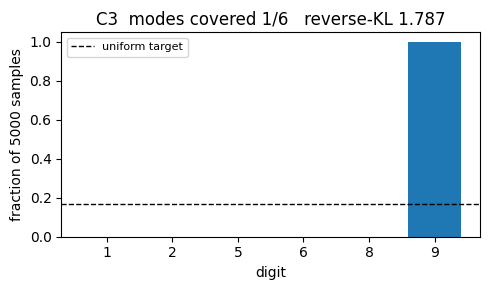

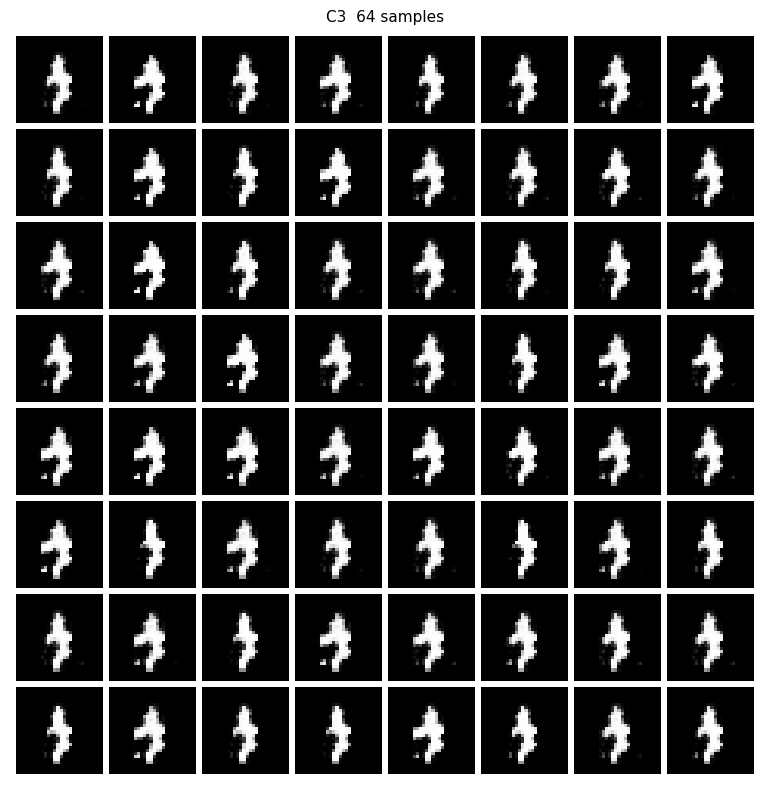

C3: modes 1/6  reverse-KL 1.7867  diversity 0.0129


In [31]:
ZDIM_C3 = 2
arr_c3, snaps_c3, G_c3, D_c3 = train_gan(
    "C3_collapse", zdim=ZDIM_C3, batchnorm_g=False,
    d_steps=1, g_steps=5, lr_d=2e-4, lr_g=2e-3, iters=1500, snap_every=100)

res_c3 = measure_model(G_c3, "C3", zdim=ZDIM_C3)

  C3_fixednoise_movement_last = 0.8036500811576843
  C3_fixednoise_movement_first = 0.9264704585075378


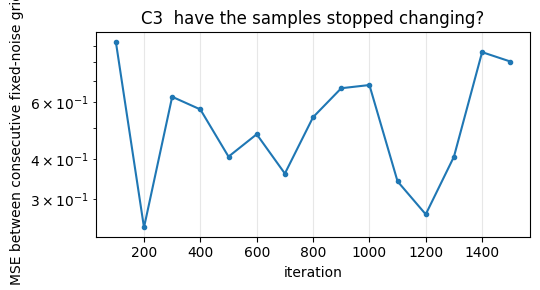

In [32]:
# did the samples stop changing? frame-to-frame movement of the SAME fixed noise
ks = sorted(snaps_c3)
mv = [float(((snaps_c3[b] - snaps_c3[a]) ** 2).mean()) for a, b in zip(ks, ks[1:])]
record("C3_fixednoise_movement_last", mv[-1])
record("C3_fixednoise_movement_first", mv[0])

plt.figure(figsize=(5.5, 3))
plt.semilogy(ks[1:], mv, marker="o", ms=3)
plt.xlabel("iteration"); plt.ylabel("MSE between consecutive fixed-noise grids")
plt.title("C3  have the samples stopped changing?"); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig("figures/C3_movement.png", dpi=140, bbox_inches="tight"); plt.show()

---
## 5 · Part D — a GAN that actually works

D1 is the 2016 recipe: strided convolutions, BatchNorm in both networks, LeakyReLU(0.2) in
D, ReLU in G, tanh output, Adam(2e-4, β₁=0.5), non-saturating loss, one D step per G step.
D2 adds **minibatch discrimination**, implemented here rather than imported — and it goes
in the discriminator, never in the generator.

[D1_dcgan] it   500/5000  d_loss 0.969  g_loss 1.364  D(x) 0.730  D(G(z)) 0.449  (7s)
[D1_dcgan] it  1000/5000  d_loss 1.163  g_loss 1.513  D(x) 0.765  D(G(z)) 0.575  (15s)
[D1_dcgan] it  1500/5000  d_loss 0.971  g_loss 1.180  D(x) 0.655  D(G(z)) 0.388  (22s)
[D1_dcgan] it  2000/5000  d_loss 0.983  g_loss 0.867  D(x) 0.533  D(G(z)) 0.236  (29s)
[D1_dcgan] it  2500/5000  d_loss 1.080  g_loss 0.994  D(x) 0.586  D(G(z)) 0.362  (36s)
[D1_dcgan] it  3000/5000  d_loss 0.991  g_loss 1.119  D(x) 0.676  D(G(z)) 0.416  (44s)
[D1_dcgan] it  3500/5000  d_loss 1.077  g_loss 1.192  D(x) 0.641  D(G(z)) 0.437  (51s)
[D1_dcgan] it  4000/5000  d_loss 1.125  g_loss 1.123  D(x) 0.672  D(G(z)) 0.477  (59s)
[D1_dcgan] it  4500/5000  d_loss 1.260  g_loss 0.778  D(x) 0.477  D(G(z)) 0.326  (66s)
[D1_dcgan] it  5000/5000  d_loss 1.110  g_loss 0.864  D(x) 0.578  D(G(z)) 0.385  (73s)
  D1_modes_covered = 6
  D1_reverse_kl = 0.018169785265105008
  D1_histogram = [0.1256, 0.2034, 0.1908, 0.126, 0.163, 0.1912]
  D1_

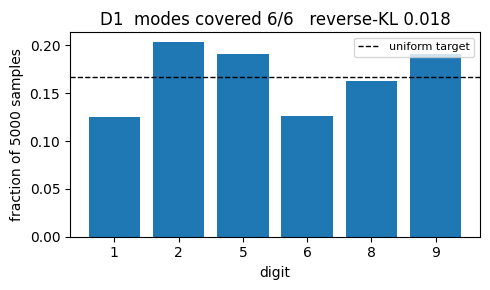

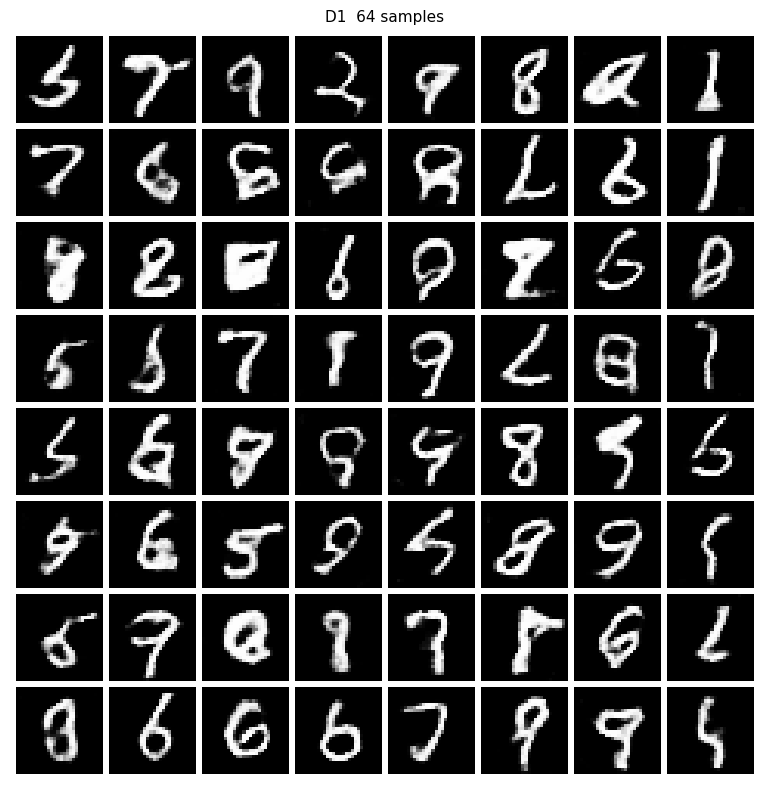

D1: modes 6/6  reverse-KL 0.0182  diversity 0.1780


In [33]:
arr_d1, snaps_d1, G_d1, D_d1 = train_gan("D1_dcgan", iters=5000, snap_every=100)
res_d1 = measure_model(G_d1, "D1")

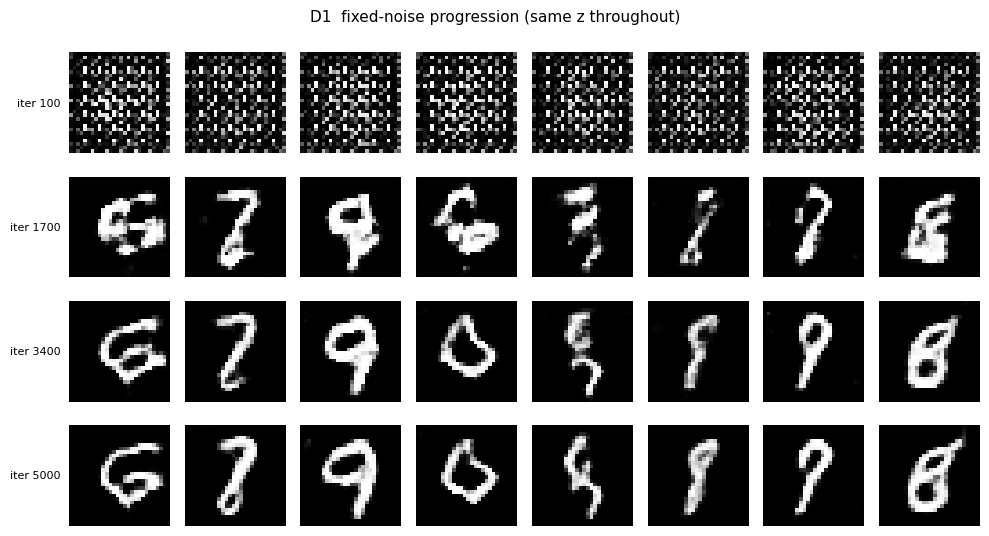

In [34]:
# the progression figure: the SAME fixed z at four points in training
ks = sorted(snaps_d1)
picks = [ks[1], ks[len(ks) // 3], ks[2 * len(ks) // 3], ks[-1]]
row_panel([to_01(snaps_d1[k])[:8] for k in picks],
          [f"iter {k}" for k in picks], ncol=8,
          title="D1  fixed-noise progression (same z throughout)",
          save="figures/D1_progression.png")

# D2

In [35]:
class MinibatchDiscrimination(nn.Module):
    """Salimans et al. 2016, written out rather than imported.
    f (N,F) -> M = f T reshaped (N,B,C); o_i,b = sum_j exp(-||M_i,b - M_j,b||_1), self
    excluded. Appending o to the features lets D see how alike the batch is, so a
    generator emitting one image is caught immediately."""
    def __init__(self, in_features, n_kernels=32, kernel_dim=8):
        super().__init__()
        self.T = nn.Parameter(torch.randn(in_features, n_kernels * kernel_dim) * 0.05)
        self.n_kernels, self.kernel_dim = n_kernels, kernel_dim

    def forward(self, f):
        M = (f @ self.T).view(-1, self.n_kernels, self.kernel_dim)       # (N,B,C)
        l1 = (M.unsqueeze(0) - M.unsqueeze(1)).abs().sum(3)              # (N,N,B)
        o  = torch.exp(-l1).sum(1) - 1.0                                 # drop the self term
        return torch.cat([f, o], dim=1)


class D28_MBD(nn.Module):
    """D28 with minibatch discrimination spliced in before the final linear.
    The convolutional trunk is identical to D28 -- only the extra feature block is new."""
    def __init__(self, ch=64, n_kernels=32, kernel_dim=8):
        super().__init__()
        self.feat = nn.Sequential(
            nn.Conv2d(1, ch, 4, 2, 1), nn.LeakyReLU(0.2, True),          # 14
            nn.Conv2d(ch, ch * 2, 4, 2, 1), nn.LeakyReLU(0.2, True),     # 7
            nn.Flatten())
        self.mbd = MinibatchDiscrimination(ch * 2 * 7 * 7, n_kernels, kernel_dim)
        self.out = nn.Linear(ch * 2 * 7 * 7 + n_kernels, 1)
    def forward(self, x): return self.out(self.mbd(self.feat(x)))        # LOGITS


# sanity check: identical batch -> large o, diverse batch -> small o
_mbd = MinibatchDiscrimination(16, 8, 4)
_same = _mbd(torch.ones(8, 16))[:, 16:].mean().item()
_diff = _mbd(torch.randn(8, 16) * 5)[:, 16:].mean().item()
print(f"minibatch feature: identical batch {_same:.3f}  vs  diverse batch {_diff:.3f}")
assert _same > _diff, "minibatch discrimination is not responding to batch similarity"

minibatch feature: identical batch 7.000  vs  diverse batch 0.228


[D2_mbd] it   500/5000  d_loss 0.015  g_loss 6.024  D(x) 0.991  D(G(z)) 0.006  (10s)
[D2_mbd] it  1000/5000  d_loss 0.039  g_loss 6.300  D(x) 0.979  D(G(z)) 0.012  (20s)
[D2_mbd] it  1500/5000  d_loss 0.174  g_loss 4.091  D(x) 0.939  D(G(z)) 0.083  (29s)
[D2_mbd] it  2000/5000  d_loss 0.016  g_loss 7.488  D(x) 0.994  D(G(z)) 0.009  (39s)
[D2_mbd] it  2500/5000  d_loss 0.071  g_loss 5.834  D(x) 0.955  D(G(z)) 0.009  (49s)
[D2_mbd] it  3000/5000  d_loss 0.020  g_loss 6.095  D(x) 0.997  D(G(z)) 0.016  (59s)
[D2_mbd] it  3500/5000  d_loss 0.028  g_loss 7.857  D(x) 0.977  D(G(z)) 0.001  (69s)
[D2_mbd] it  4000/5000  d_loss 0.046  g_loss 9.990  D(x) 0.996  D(G(z)) 0.020  (79s)
[D2_mbd] it  4500/5000  d_loss 0.073  g_loss 10.430  D(x) 0.999  D(G(z)) 0.043  (88s)
[D2_mbd] it  5000/5000  d_loss 0.085  g_loss 7.011  D(x) 0.998  D(G(z)) 0.039  (98s)
  D2_modes_covered = 6
  D2_reverse_kl = 0.06648935143000054
  D2_histogram = [0.1478, 0.1356, 0.2218, 0.0676, 0.2422, 0.185]
  D2_sample_diversity_s

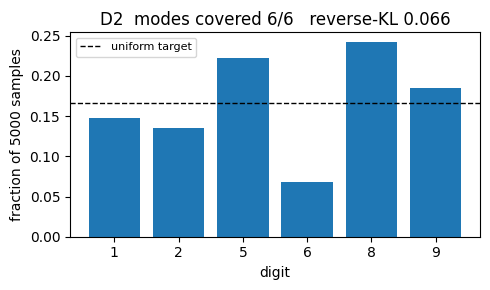

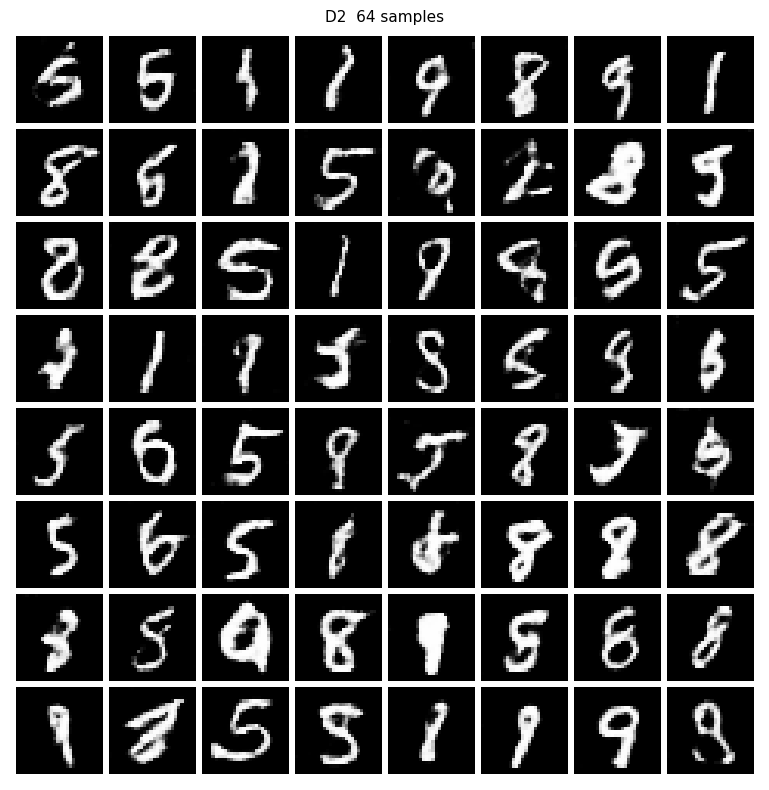

D2: modes 6/6  reverse-KL 0.0665  diversity 0.1731


In [36]:
arr_d2, snaps_d2, G_d2, D_d2 = train_gan("D2_mbd", D_factory=lambda: D28_MBD(),
                                          iters=5000, snap_every=100)
res_d2 = measure_model(G_d2, "D2")

model                   modes   reverse-KL   diversity
C3 collapsed            1/6         1.7867      0.0129
D1 DCGAN                6/6         0.0182      0.1780
D2 + minibatch disc     6/6         0.0665      0.1731


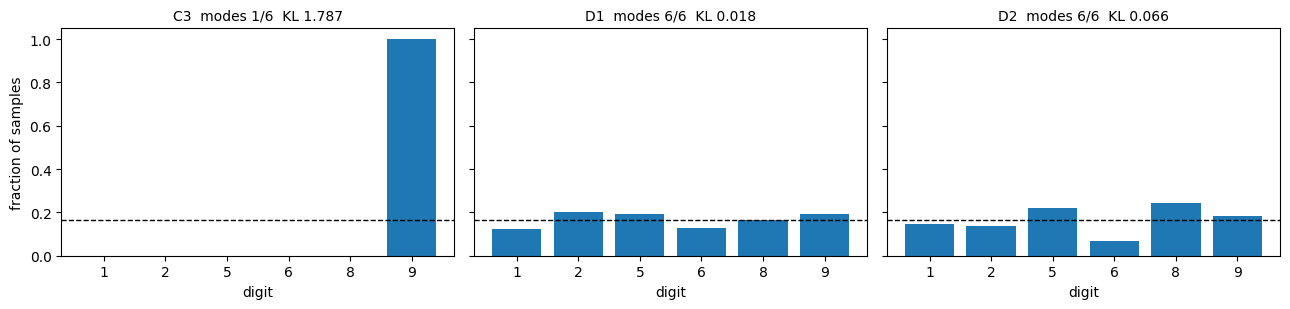

In [37]:
# the D2 table, IS and FID columns filled in Part E
print(f"{'model':<22}{'modes':>7}{'reverse-KL':>13}{'diversity':>12}")
for tag, name in [("C3", "C3 collapsed"), ("D1", "D1 DCGAN"), ("D2", "D2 + minibatch disc")]:
    r = GEN[tag]
    print(f"{name:<22}{r['modes']:>3}/{len(MY_DIGITS):<3}{r['rev_kl']:>13.4f}"
          f"{float(r['images'].std(0).mean()):>12.4f}")

fig, axs = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, tag in zip(axs, ["C3", "D1", "D2"]):
    ax.bar([str(d) for d in MY_DIGITS], GEN[tag]["p_gen"], color="tab:blue")
    ax.axhline(1 / len(MY_DIGITS), ls="--", c="k", lw=1)
    ax.set_title(f"{tag}  modes {GEN[tag]['modes']}/{len(MY_DIGITS)}  "
                 f"KL {GEN[tag]['rev_kl']:.3f}", fontsize=10)
    ax.set_xlabel("digit")
axs[0].set_ylabel("fraction of samples")
plt.tight_layout(); plt.savefig("figures/D2_histograms.png", dpi=140, bbox_inches="tight")
plt.show()

---
## 5 · Part E — Inception Score and FID

softmax for IS, the 128-d penultimate features for FID.
*Still to be written.*

Both written from the formulas, using the classifier from 4.1: its softmax gives p(y|x)
for IS, its 128-d penultimate layer gives the features for FID. No `pytorch-fid`, no
`clean-fid`, no scikit-learn — only NumPy and `scipy.linalg.sqrtm` for the matrix square
root.

In [39]:


def inception_score(probs, splits=10):
    """IS = exp( E_x [ D_KL( p(y|x) || p(y) ) ] ), over `splits` disjoint chunks.
    Returns (mean, std) across the splits."""
    probs = np.asarray(probs, dtype=np.float64)
    n = len(probs)
    scores = []
    for s in range(splits):
        p_yx = probs[s * n // splits:(s + 1) * n // splits]          # (n_s, K)
        p_y  = p_yx.mean(0, keepdims=True)                           # (1, K) marginal
        kl   = (p_yx * (np.log(p_yx + 1e-12) - np.log(p_y + 1e-12))).sum(1).mean()
        scores.append(float(np.exp(kl)))
    return float(np.mean(scores)), float(np.std(scores))


def frechet_distance(feat_real, feat_gen, eps=1e-6):
    """FID = ||mu_r - mu_g||^2 + Tr( S_r + S_g - 2 (S_r S_g)^(1/2) )."""
    fr = np.asarray(feat_real, dtype=np.float64)
    fg = np.asarray(feat_gen,  dtype=np.float64)
    mu_r, mu_g = fr.mean(0), fg.mean(0)
    S_r,  S_g  = np.cov(fr, rowvar=False), np.cov(fg, rowvar=False)

    def _sqrtm(M):                                  # `disp` is deprecated in modern SciPy
        out = linalg.sqrtm(M)
        return out[0] if isinstance(out, tuple) else out

    covmean = _sqrtm(S_r @ S_g)
    if not np.isfinite(covmean).all():              # singular product -> nudge diagonals
        off = np.eye(S_r.shape[0]) * eps
        covmean = _sqrtm((S_r + off) @ (S_g + off))

    # S_r S_g is a product of two PSD matrices, so its eigenvalues are real and >= 0 and
    # the true square root is real. Tiny imaginary parts are floating-point error in the
    # Schur decomposition, not signal -- but check the magnitude before discarding them.
    imag = float(np.abs(covmean.imag).max()) if np.iscomplexobj(covmean) else 0.0
    if imag > 1e-3:
        print(f"  WARNING: large imaginary component {imag:.3e} -- check the features")
    covmean = covmean.real

    diff = mu_r - mu_g
    return float(diff @ diff + np.trace(S_r + S_g - 2 * covmean)), imag


# ---- self-tests: the two values we can work out by hand ----
_k = len(MY_DIGITS)
# 1200 = 10 splits x 120, and 120 is divisible by K, so each split is EXACTLY uniform
_onehot = np.eye(_k)[np.arange(1200) % _k]                 # confident AND uniform
assert abs(inception_score(_onehot)[0] - _k) < 1e-6, "IS of a perfect classifier == K"
_flat = np.full((1200, _k), 1 / _k)                        # maximally unsure
assert abs(inception_score(_flat)[0] - 1.0) < 1e-6, "IS of a uniform predictor == 1"
_f = np.random.RandomState(0).randn(500, 32)
assert abs(frechet_distance(_f, _f)[0]) < 1e-6, "FID(X, X) == 0"
print("inception_score and frechet_distance self-tests passed")

inception_score and frechet_distance self-tests passed


  C1_modes_covered = 2
  C1_reverse_kl = 1.6288339478327638
  C1_histogram = [0.0, 0.0012, 0.0356, 0.0, 0.9632, 0.0]
  C1_sample_diversity_std = 0.21061019599437714


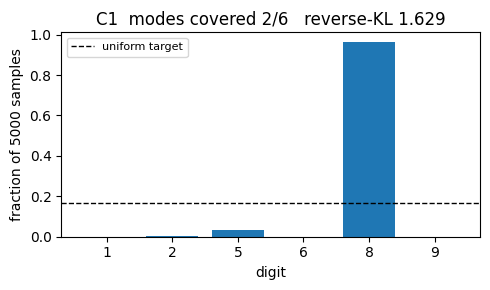

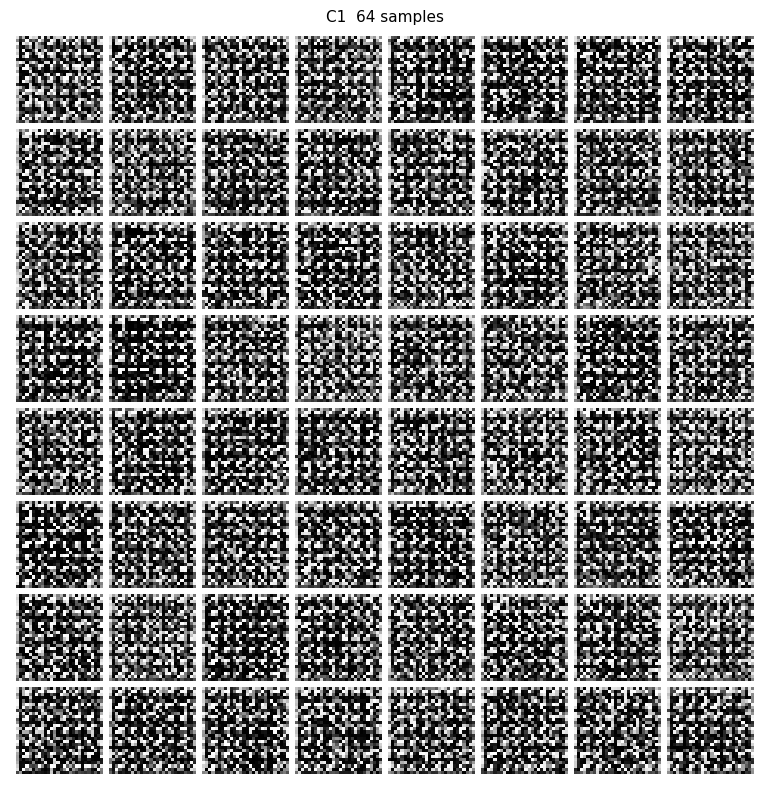

C1: modes 2/6  reverse-KL 1.6288  diversity 0.2106
collected: ['C1', 'C3', 'D1', 'D2', 'real']


In [40]:
# ---- the five sets: real, C1, C3, D1, D2 ----
def get_real(ds, n, offset=0):
    g = torch.Generator().manual_seed(SEED + offset)
    idx = torch.randperm(len(ds), generator=g)[:n]
    return torch.stack([ds[int(i)][0] for i in idx])


real_ref  = get_real(mnist_mine, 10000, offset=0)    # FID reference: real TRAINING set
real_eval = get_real(mnist_mine,  5000, offset=1)    # the "real data" row of the table
probs_ref, feats_ref = classify(clf, real_ref)
probs_re,  feats_re  = classify(clf, real_eval)
GEN["real"] = dict(images=real_eval, probs=probs_re, feats=feats_re)

res_c1 = measure_model(G_c1, "C1")        # C1's generator, for the E1/E2 table
print("collected:", sorted(GEN))

In [41]:
rows = []
for tag, name in [("real", "real data"), ("C1", "C1 saturating"), ("C3", "C3 collapsed"),
                  ("D1", "D1 DCGAN"), ("D2", "D2 + minibatch")]:
    is_m, is_s = inception_score(GEN[tag]["probs"], splits=10)
    fid, imag  = frechet_distance(feats_ref, GEN[tag]["feats"])
    record(f"E1_IS_{tag}",  [is_m, is_s])
    record(f"E2_FID_{tag}", fid)
    record(f"E2_FID_sqrtm_imag_{tag}", imag)
    rows.append((name, is_m, is_s, fid,
                 GEN[tag].get("modes", "-"), GEN[tag].get("rev_kl", float("nan"))))

print(f"\n{'model':<18}{'modes':>7}{'rev-KL':>10}{'IS (mean +- std)':>22}{'FID':>10}")
for name, im, isd, fid, modes, kl in rows:
    m = f"{modes}/{len(MY_DIGITS)}" if modes != "-" else "-"
    k = "-" if kl != kl else f"{kl:.4f}"
    print(f"{name:<18}{m:>7}{k:>10}{im:>14.3f} +- {isd:<6.3f}{fid:>10.3f}")

/tmp/ipykernel_58/948824681.py:23: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  out = linalg.sqrtm(M)


  E1_IS_real = [5.6979842719609435, 0.03119489910739666]
  E2_FID_real = 0.3228424068951362
  E2_FID_sqrtm_imag_real = 0.0
  E1_IS_C1 = [1.0929399145021115, 0.004220897752950004]
  E2_FID_C1 = 624.3088853510433
  E2_FID_sqrtm_imag_C1 = 0.0
  E1_IS_C3 = [1.0419787081456708, 0.0015713317747090454]
  E2_FID_C3 = 670.6616125164088
  E2_FID_sqrtm_imag_C3 = 0.0
  E1_IS_D1 = [4.118570114584493, 0.07744322485799203]
  E2_FID_D1 = 27.484660192116387
  E2_FID_sqrtm_imag_D1 = 0.0
  E1_IS_D2 = [4.205579909813735, 0.06550673440496455]
  E2_FID_D2 = 38.75442625724334
  E2_FID_sqrtm_imag_D2 = 0.0

model               modes    rev-KL      IS (mean +- std)       FID
real data               -         -         5.698 +- 0.031      0.323
C1 saturating         2/6    1.6288         1.093 +- 0.004    624.309
C3 collapsed          1/6    1.7867         1.042 +- 0.002    670.662
D1 DCGAN              6/6    0.0182         4.119 +- 0.077     27.485
D2 + minibatch        6/6    0.0665         4.206 +- 0.066    

In [42]:
# ---- E3 (a) the floor: FID between two disjoint halves of the REAL test set ----
te_all = torch.stack([mnist_mine_te[i][0] for i in range(len(mnist_mine_te))])
g = torch.Generator().manual_seed(SEED)
perm_te = torch.randperm(len(te_all), generator=g)
h1, h2 = te_all[perm_te[:len(te_all) // 2]], te_all[perm_te[len(te_all) // 2:]]
fid_floor, _ = frechet_distance(classify(clf, h1)[1], classify(clf, h2)[1])
record("E3_fid_floor", fid_floor)
record("E3_fid_floor_n_per_half", len(h1))

  E3_fid_floor = 0.5682001251938553
  E3_fid_floor_n_per_half = 3000


/tmp/ipykernel_58/948824681.py:23: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  out = linalg.sqrtm(M)


/tmp/ipykernel_58/948824681.py:23: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  out = linalg.sqrtm(M)


  sigma 0.0   FID    0.375
  sigma 0.1   FID    7.230
  sigma 0.25  FID   60.139
  sigma 0.5   FID  265.193
  sigma 1.0   FID  566.696
  E3_fid_vs_sigma = {'0.0': 0.3754939644873507, '0.1': 7.229588539193987, '0.25': 60.13924892051349, '0.5': 265.19320719648545, '1.0': 566.6963179093136}
  E3_monotone = True


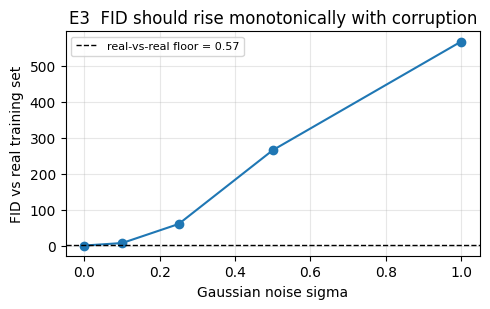

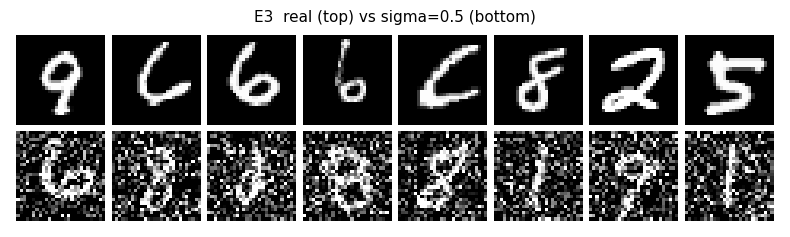

In [43]:
# ---- E3 (b) monotonicity: FID(real, real + sigma*noise) ----
sigmas = [0.0, 0.1, 0.25, 0.5, 1.0]
fids_sigma = []
base = get_real(mnist_mine, 5000, offset=2)
for s in sigmas:
    gg = torch.Generator().manual_seed(SEED)
    noisy = (base + s * torch.randn(base.shape, generator=gg)).clamp(0, 1)
    f, _ = frechet_distance(feats_ref, classify(clf, noisy)[1])
    fids_sigma.append(f)
    print(f"  sigma {s:<5} FID {f:8.3f}")
record("E3_fid_vs_sigma", dict(zip(map(str, sigmas), fids_sigma)))
record("E3_monotone", bool(all(b >= a for a, b in zip(fids_sigma, fids_sigma[1:]))))

plt.figure(figsize=(5, 3.2))
plt.plot(sigmas, fids_sigma, marker="o")
plt.axhline(fid_floor, ls="--", c="k", lw=1, label=f"real-vs-real floor = {fid_floor:.2f}")
plt.xlabel("Gaussian noise sigma"); plt.ylabel("FID vs real training set")
plt.title("E3  FID should rise monotonically with corruption")
plt.legend(fontsize=8); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig("figures/E3_fid_monotonicity.png", dpi=140, bbox_inches="tight"); plt.show()

show_grid(torch.cat([h1[:8], (base[:8] + 0.5 * torch.randn(base[:8].shape)).clamp(0, 1)]),
          nrow=8, figsize=(8, 2.4), title="E3  real (top) vs sigma=0.5 (bottom)",
          save="figures/E3_noise_examples.png")

In [44]:
# ---- the final table, all columns filled ----
print(f"{'model':<18}{'modes':>7}{'rev-KL':>10}{'IS':>16}{'FID':>10}")
for tag, name in [("real", "real data"), ("C1", "C1 saturating"), ("C3", "C3 collapsed"),
                  ("D1", "D1 DCGAN"), ("D2", "D2 + minibatch")]:
    is_m, is_s = METRICS[f"E1_IS_{tag}"]
    fid = METRICS[f"E2_FID_{tag}"]
    modes = GEN[tag].get("modes", "-")
    kl = GEN[tag].get("rev_kl", float("nan"))
    m = f"{modes}/{len(MY_DIGITS)}" if modes != "-" else "-"
    k = "-" if kl != kl else f"{kl:.4f}"
    print(f"{name:<18}{m:>7}{k:>10}{is_m:>10.3f}+-{is_s:<5.3f}{fid:>10.3f}")
print(f"\nFID floor (real test halves, n={METRICS['E3_fid_floor_n_per_half']} each): "
      f"{METRICS['E3_fid_floor']:.3f}")
print(f"FID monotone in sigma: {METRICS['E3_monotone']}")

print("\nE3 (c) -- the numbers your paragraph needs:")
print(f"  C3 collapsed : IS {METRICS['E1_IS_C3'][0]:.3f}   FID {METRICS['E2_FID_C3']:.3f}   "
      f"modes {GEN['C3']['modes']}/{len(MY_DIGITS)}")
print(f"  D1 DCGAN     : IS {METRICS['E1_IS_D1'][0]:.3f}   FID {METRICS['E2_FID_D1']:.3f}   "
      f"modes {GEN['D1']['modes']}/{len(MY_DIGITS)}")

model               modes    rev-KL              IS       FID
real data               -         -     5.698+-0.031     0.323
C1 saturating         2/6    1.6288     1.093+-0.004   624.309
C3 collapsed          1/6    1.7867     1.042+-0.002   670.662
D1 DCGAN              6/6    0.0182     4.119+-0.077    27.485
D2 + minibatch        6/6    0.0665     4.206+-0.066    38.754

FID floor (real test halves, n=3000 each): 0.568
FID monotone in sigma: True

E3 (c) -- the numbers your paragraph needs:
  C3 collapsed : IS 1.042   FID 670.662   modes 1/6
  D1 DCGAN     : IS 4.119   FID 27.485   modes 6/6
